# Análisis de Datos - Actividad Individual 2: Análisis Exploratorio de Datos (EDA)

## Estudio de Integridad, Población, Parámetros Morfológicos y Outliers en Pingüinos del Archipiélago Palmer

**Alumno:** Juan Ignacio Bohner

**Dataset:** `penguins_lter.csv` (Long Term Ecological Research - Palmer Station, Antártida)

---

### Objetivos del Análisis Exploratorio de Datos (EDA):
1. **Contexto e Introducción:** Presentar el origen del relevamiento de campo en el Archipiélago Palmer y su ubicación geográfica mediante fotografía satelital real.
2. **Integridad del Dataset y Análisis de Faltantes:** Evaluar la presencia, distribución y correlación de datos nulos para determinar sus mecanismos (MCAR, MAR, MNAR).
3. **Población Registrada:** Analizar la composición de la muestra (por especie, por isla y por sexo).
4. **Exploración Univariada de Variables Continuas:** Evaluar de forma exhaustiva cada variable numérica con su histograma, curva KDE, **Media, Varianza, Desvío Estándar (Std), Asimetría (Skewness) y Curtosis**.
5. **Detección y Estudio de Outliers:** Identificar formalmente valores atípicos tanto a nivel global como estratificado por especie.
6. **Análisis Bivariado, Multivariado y Dimorfismo Sexual:** Explorar la Paradoja de Simpson en la morfología del pico, alometría en aletas/peso, dimorfismo sexual y mapas de correlación lineal y monótona.

## 1. Introducción y Contexto Geográfico

El conjunto de datos contiene los registros de un estudio ecológico de monitoreo de largo plazo liderado por la **Dra. Kristen Gorman** en la **Estación Palmer LTER** (*Palmer Station Antarctica LTER*, parte de la *Long Term Ecological Research Network*).

Las mediciones se realizaron durante tres temporadas reproductivas consecutivas (veranos australes de 2007/08, 2008/09 y 2009/10) en tres islas situadas en las inmediaciones de la **Isla Anvers**, en el **Archipiélago Palmer** (Península Antártica):
* **Isla Torgersen** (64°46'S, 64°05'W): colonia exclusiva de *Adelie*.
* **Isla Dream** (64°44'S, 64°14'W): coexisten colonias de *Adelie* y *Chinstrap*.
* **Punta Biscoe / Islas Biscoe** (64°49'S, 63°48'W): coexisten colonias de *Adelie* y *Gentoo*.

In [2]:
import io
import os
import urllib.request
import warnings
from pathlib import Path

# Soporte seguro de display en entornos interactivos
try:
    from IPython.display import HTML, display
except ImportError:
    HTML = lambda *args, **kwargs: None
    def display(*args, **kwargs):
        pass

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
from PIL import Image
import seaborn as sns
from scipy import stats

# Configuración estética general
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.unicode_minus"] = False

# Paleta cromática oficial y consistente para las tres especies
SPECIES_COLORS = {
    "Adelie": "#e67e22",     # Naranja cálido
    "Chinstrap": "#9b59b6",  # Púrpura / violeta
    "Gentoo": "#1abc9c"      # Verde azulado / turquesa
}

### 1.1. Localización Geográfica: Fotografía Satelital del Archipiélago Palmer
Proyectamos las coordenadas reales (WGS84) de las colonias y de la base científica sobre una **fotografía satelital de alta resolución** (NASA / USGS / Esri World Imagery) de la Isla Anvers y el Archipiélago Palmer.

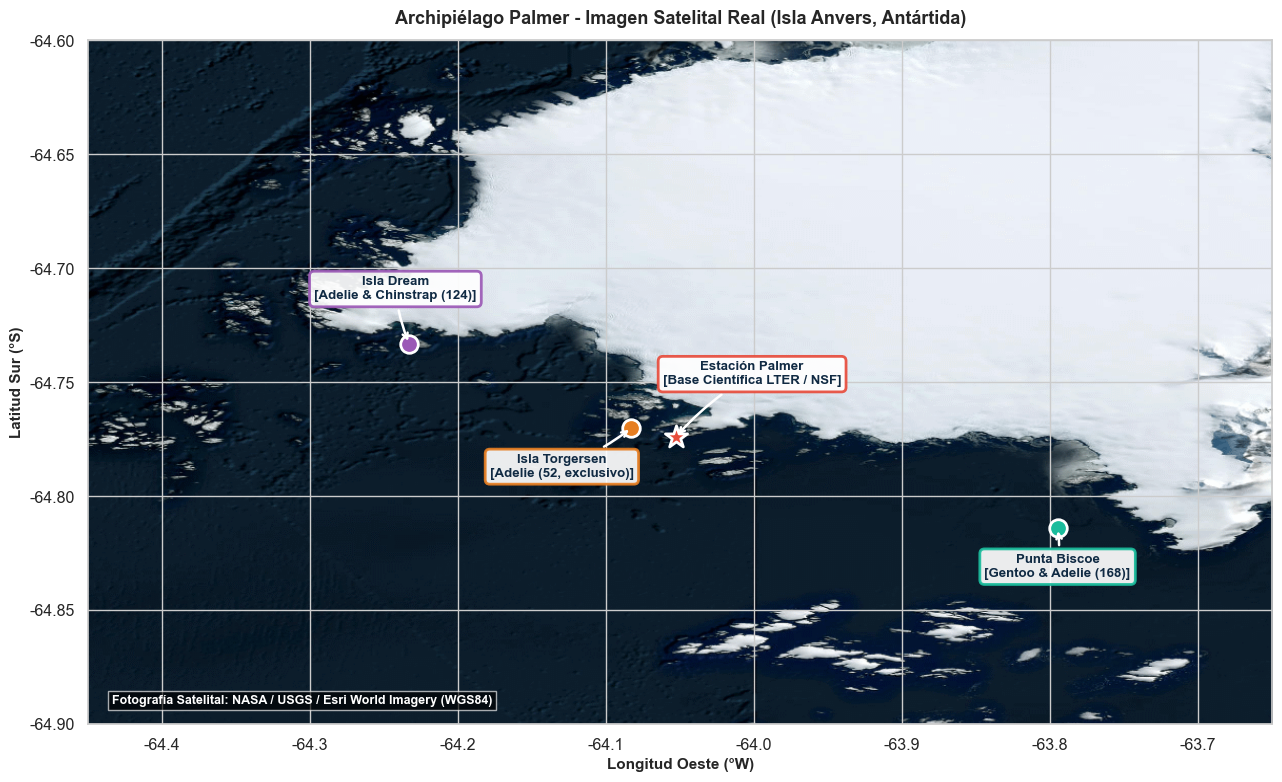

In [3]:
# Coordenadas y metadatos de las colonias de pingüinos y la base científica
sites_geo = [
    {
        "name": "Isla Dream",
        "species": "Adelie & Chinstrap (124)",
        "lat": -64.733, "lon": -64.233,
        "col": "#9b59b6",
        "offset": (-10, 32),
        "desc": "Única isla del estudio con presencia de pingüinos barbijo (Chinstrap)."
    },
    {
        "name": "Isla Torgersen",
        "species": "Adelie (52, exclusivo)",
        "lat": -64.770, "lon": -64.083,
        "col": "#e67e22",
        "offset": (-50, -35),
        "desc": "Colonia histórica monotípica a 1 km al oeste de Palmer Station."
    },
    {
        "name": "Estación Palmer",
        "species": "Base Científica LTER / NSF",
        "lat": -64.774, "lon": -64.053,
        "col": "#e74c3c",
        "offset": (55, 38),  # Viene desde arriba a la derecha para no solapar a Torgersen
        "desc": "Base antártica de investigación permanente de EE.UU."
    },
    {
        "name": "Punta Biscoe",
        "species": "Gentoo & Adelie (168)",
        "lat": -64.814, "lon": -63.795,
        "col": "#1abc9c",
        "offset": (0, -35),
        "desc": "Península / islas al sureste; único sitio donde anida Gentoo."
    }
]

# Búsqueda de imagen satelital local o descarga automática con User-Agent seguro
img_candidates = [
    Path("img/satelite_palmer_real.png"),
    Path("datasets/Actividades/Act_2/img/satelite_palmer_real.png"),
    Path("Análisis de Datos/datasets/Actividades/Act_2/img/satelite_palmer_real.png"),
    Path(r"C:\Users\juanb\Documents\FIUBA\CEIA\Análisis de Datos\datasets\Actividades\Act_2\img\satelite_palmer_real.png")
]

sat_img_path = None
for p in img_candidates:
    if p.exists():
        sat_img_path = p
        break

if sat_img_path is None:
    print("Descargando imagen satelital real para el mapa...")
    sat_url = "https://services.arcgisonline.com/arcgis/rest/services/World_Imagery/MapServer/export?bbox=-64.50,-64.95,-63.60,-64.55&bboxSR=4326&imageSR=4326&size=1400,900&f=image"
    req = urllib.request.Request(sat_url, headers={"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"})
    try:
        with urllib.request.urlopen(req) as resp:
            sat_img = Image.open(io.BytesIO(resp.read())).convert("RGB")
    except Exception as e:
        print(f"Aviso: satélite no descargado ({e}), se graficará fondo esquemático.")
        sat_img = None
else:
    sat_img = Image.open(sat_img_path).convert("RGB")

fig, ax = plt.subplots(figsize=(13, 8))
extent = [-64.50, -63.60, -64.95, -64.55]

if sat_img is not None:
    ax.imshow(sat_img, extent=extent, aspect="auto")
else:
    ax.set_facecolor("#e8f4f8")

for s in sites_geo:
    is_station = "Estación" in s["name"]
    marker = "*" if is_station else "o"
    size = 280 if is_station else 160
    
    ax.scatter(
        s["lon"], s["lat"],
        color=s["col"],
        s=size,
        marker=marker,
        edgecolors="white",
        linewidth=2,
        zorder=5
    )
    
    ax.annotate(
        f"{s['name']}\n[{s['species']}]",
        xy=(s["lon"], s["lat"]),
        xytext=s["offset"],
        textcoords="offset points",
        ha="center",
        fontsize=9.5,
        weight="bold",
        color="#102a43",
        bbox=dict(boxstyle="round,pad=0.35", fc="white", ec=s["col"], alpha=0.92, lw=2),
        arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.08", color="white", lw=1.8),
        zorder=6
    )

ax.set_xlim(-64.45, -63.65)
ax.set_ylim(-64.90, -64.60)
ax.set_xlabel("Longitud Oeste (°W)", fontsize=11, weight="bold")
ax.set_ylabel("Latitud Sur (°S)", fontsize=11, weight="bold")
ax.set_title("Archipiélago Palmer - Imagen Satelital Real (Isla Anvers, Antártida)", fontsize=13, weight="bold", pad=12)
ax.text(0.02, 0.03, "Fotografía Satelital: NASA / USGS / Esri World Imagery (WGS84)", transform=ax.transAxes,
        fontsize=9, color="white", weight="bold", bbox=dict(boxstyle="square,pad=0.3", fc="black", alpha=0.65))

plt.tight_layout()
plt.show()

## 2. Carga y Preparación de Datos

Cargamos el archivo original `penguins_lter.csv` (17 variables de campo) y preparamos las columnas para el análisis.

In [4]:
# Resolución dinámica de rutas compatible con cualquier entorno
CANDIDATE_PATHS = [
    Path("penguins_lter.csv"),
    Path("../Act_1/penguins_lter.csv"),
    Path("../../datasets/Actividades/Act_1/penguins_lter.csv"),
    Path("datasets/Actividades/Act_1/penguins_lter.csv"),
    Path("Análisis de Datos/datasets/Actividades/Act_1/penguins_lter.csv"),
    Path(r"C:\Users\juanb\Documents\FIUBA\CEIA\Análisis de Datos\datasets\Actividades\Act_1\penguins_lter.csv")
]

FILE_PATH = None
for cand in CANDIDATE_PATHS:
    if cand.resolve().exists():
        FILE_PATH = cand.resolve()
        break

if FILE_PATH is None:
    raise FileNotFoundError("No se encontró el archivo 'penguins_lter.csv'.")

df_raw = pd.read_csv(FILE_PATH)
print(f"[OK] Dataset cargado exitosamente desde: {FILE_PATH}")
print(f"Dimensiones: {df_raw.shape[0]} filas × {df_raw.shape[1]} columnas")

# Preparación y limpieza de columnas
df = df_raw.copy()

def extract_species_name(full_name):
    if "Adelie" in full_name:
        return "Adelie"
    elif "Chinstrap" in full_name:
        return "Chinstrap"
    elif "Gentoo" in full_name:
        return "Gentoo"
    return full_name

df["species_short"] = df["Species"].apply(extract_species_name)
df["Sex"] = df["Sex"].replace(".", np.nan)
df["Year"] = pd.to_datetime(df["Date Egg"]).dt.year

# Renombrado sintáctico de variables numéricas continuas
df["culmen_length_mm"] = df["Culmen Length (mm)"]
df["culmen_depth_mm"] = df["Culmen Depth (mm)"]
df["flipper_length_mm"] = df["Flipper Length (mm)"]
df["body_mass_g"] = df["Body Mass (g)"]
df["delta_15_n"] = df["Delta 15 N (o/oo)"]
df["delta_13_c"] = df["Delta 13 C (o/oo)"]

display(df[["species_short", "Island", "Sex", "culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g", "delta_15_n", "delta_13_c"]].head(3))

[OK] Dataset cargado exitosamente desde: C:\Users\juanb\Documents\FIUBA\CEIA\Análisis de Datos\datasets\Actividades\Act_1\penguins_lter.csv
Dimensiones: 344 filas × 17 columnas


,species_short,Island,Sex,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,delta_15_n,delta_13_c
0,Adelie,Torgersen,MALE,39.1,18.7,181.0,3750.0,NaN,NaN
1,Adelie,Torgersen,FEMALE,39.5,17.4,186.0,3800.0,8.94956,-24.69454
2,Adelie,Torgersen,FEMALE,40.3,18.0,195.0,3250.0,8.36821,-25.33302


### Clasificación de las 15 Variables del Dataset

A partir de la inspección inicial, las variables se agrupan de la siguiente forma:

* **Numéricas Continuas (6):** `Culmen Length (mm)`, `Culmen Depth (mm)`, `Flipper Length (mm)`, `Body Mass (g)`, `Delta 15 N (o/oo)` y `Delta 13 C (o/oo)` *(dimensiones físicas, peso y mediciones isotópicas)*.
* **Numéricas Discretas (1):** `Sample Number` *(conteo / número correlativo de muestra)*.
* **Categóricas Nominales (5):** `Species`, `Island`, `studyName`, `Region` y `Stage` *(categorías cualitativas no jerárquicas)*.
* **Categóricas Binarias (2):** `Sex` (*MALE / FEMALE*) y `Clutch Completion` (*Yes / No*).
* **Temporal / Fecha (1):** `Date Egg` *(fecha de registro de la nidada)*.



Dos columnas son de los siguientes campos:
* **Identificador:** `Individual ID` *(código unívoco del anillo de identificación)*
*  **Texto Libre:** `Comments` *(observaciones de campo)*


## 3. Estudio de Integridad del Dataset y Análisis de Datos Faltantes

Analizamos la integridad y completitud de las variables con la biblioteca especializada `missingno`:
1. **`msno.matrix`:** Muestra la presencia (color sólido) y ausencia (espacio en blanco) en cada fila a lo largo del dataset, junto a una línea de conteo a la derecha (*sparkline*).
2. **`msno.bar`:** Conteo absoluto y porcentaje exacto de completitud por variable.
3. **`msno.heatmap`:** Correlación de nulidad para identificar dependencias entre los datos faltantes.

<Figure size 1600x600 with 0 Axes>

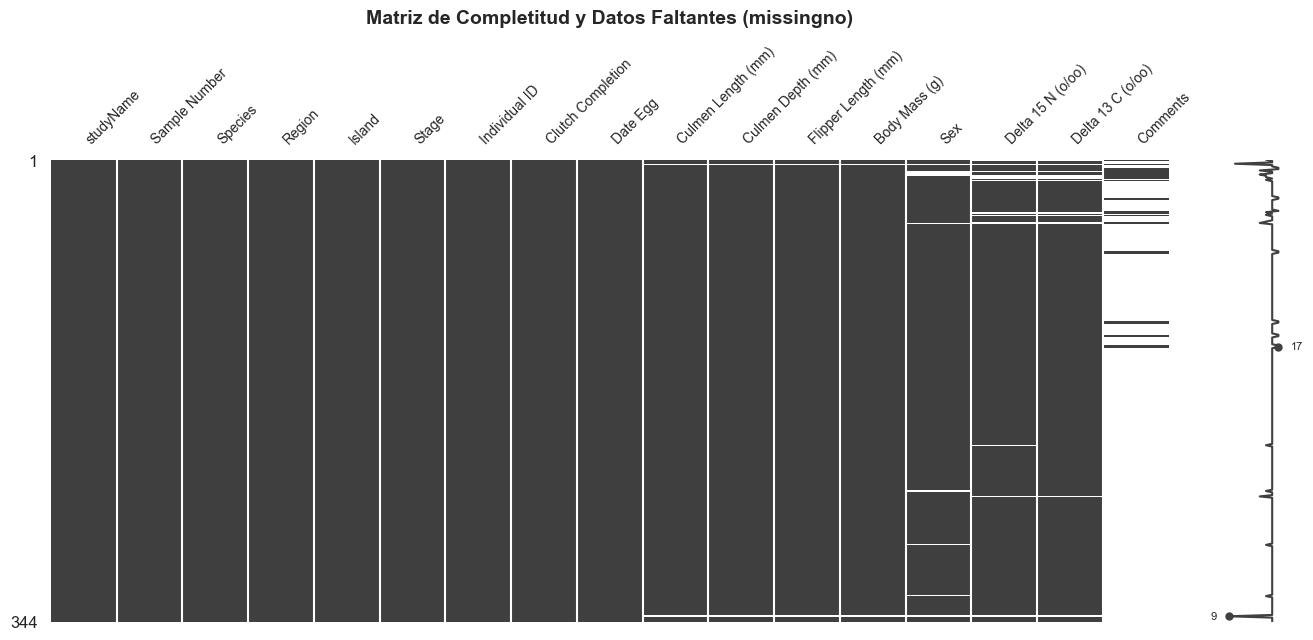

In [5]:
# 1. Matriz de completitud del dataset
plt.figure(figsize=(16, 6))
msno.matrix(df_raw, figsize=(16, 6), fontsize=10, sparkline=True)
plt.title("Matriz de Completitud y Datos Faltantes (missingno)", fontsize=14, weight="bold", pad=15)
plt.show()

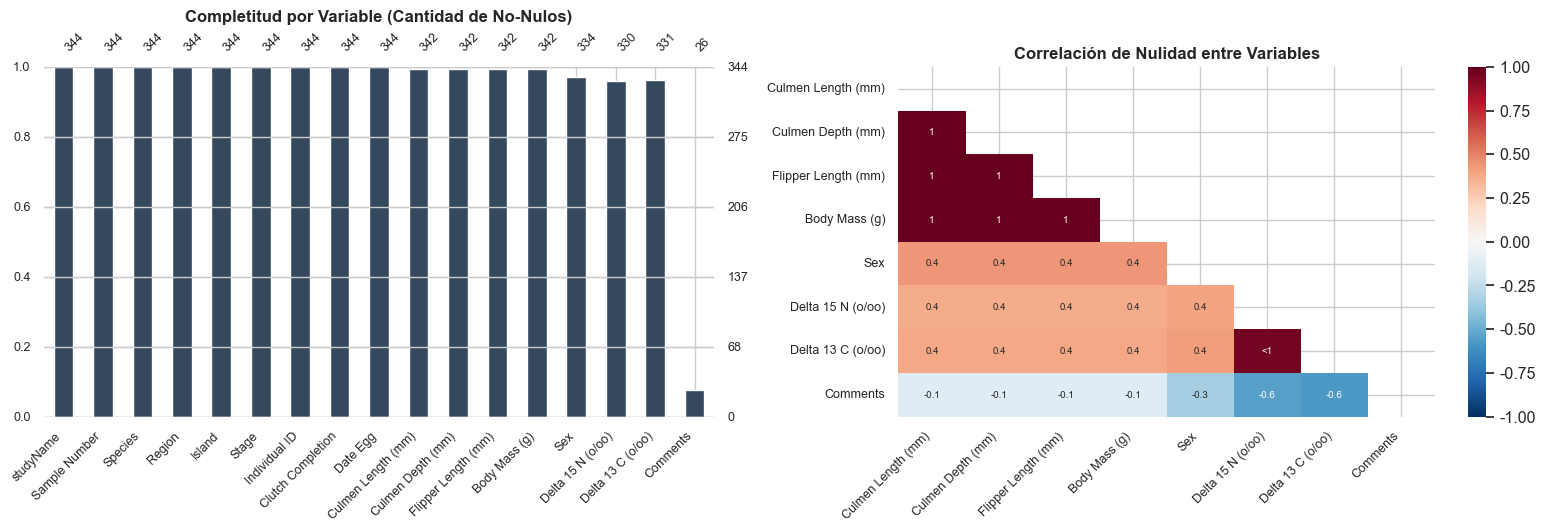

In [6]:
# 2. Gráfico de barras de completitud y 3. Mapa de calor de correlación de nulos
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Bar chart de missingno en el primer eje
msno.bar(df_raw, ax=axes[0], fontsize=9, color="#34495e")
axes[0].set_title("Completitud por Variable (Cantidad de No-Nulos)", fontsize=12, weight="bold")

# Heatmap de correlación de nulos en el segundo eje
msno.heatmap(df_raw, ax=axes[1], fontsize=9, cmap="RdBu_r")
axes[1].set_title("Correlación de Nulidad entre Variables", fontsize=12, weight="bold")

plt.tight_layout()
plt.show()

In [7]:
# Tabla cuantitativa de nulos
null_summary = pd.DataFrame({
    "Tipo de Variable": df_raw.dtypes,
    "Datos Presentes": df_raw.notnull().sum(),
    "Datos Faltantes": df_raw.isnull().sum(),
    "% Faltante": (df_raw.isnull().mean() * 100).round(2)
}).sort_values(by="Datos Faltantes", ascending=False)

print("=== Resumen Cuantitativo de Datos Faltantes ===")
display(null_summary[null_summary["Datos Faltantes"] > 0])

=== Resumen Cuantitativo de Datos Faltantes ===


,Tipo de Variable,Datos Presentes,Datos Faltantes,% Faltante
Comments,object,26,318,92.44
Delta 15 N (o/oo),float64,330,14,4.07
Delta 13 C (o/oo),float64,331,13,3.78
Sex,object,334,10,2.91
Culmen Length (mm),float64,342,2,0.58
Flipper Length (mm),float64,342,2,0.58
Culmen Depth (mm),float64,342,2,0.58
Body Mass (g),float64,342,2,0.58


#### Diagnóstico sobre la Integridad del Dataset:
* **`Comments` (92.4% faltante):** Es un campo de texto libre para notas extraordinarias (ej. *"Not enough blood for isotopes"*). Su ausencia es natural y esperable.
* **Medidas Morfológicas (0.58% faltante):** Exactamente **2 individuos** carecen simultáneamente de las 4 medidas físicas (`Culmen Length`, `Culmen Depth`, `Flipper Length` y `Body Mass`). Su correlación de nulidad es perfecta ($r = 1.0$), sugiriendo un mecanismo **MCAR** (*Missing Completely at Random*. Podría haber ocurrido por pingüinos que se escaparon antes del pesaje y medición).
* **`Sex` (3.2% faltante):** 11 individuos no poseen registro de sexo o tenían el caracter erróneo `.`. En pingüinos el sexo no es evidente a simple vista y requiere un análisis profundo.
* **Isótopos (`Delta 15 N` y `Delta 13 C`) (3.8% - 4.1% faltante):** 14 y 13 pingüinos no cuentan con medición isotópica por escasez de muestra sanguínea en el laboratorio.

## 4. Análisis de la Población Registrada

Examinamos la estructura demográfica del censo mediante gráficos de torta y barras.

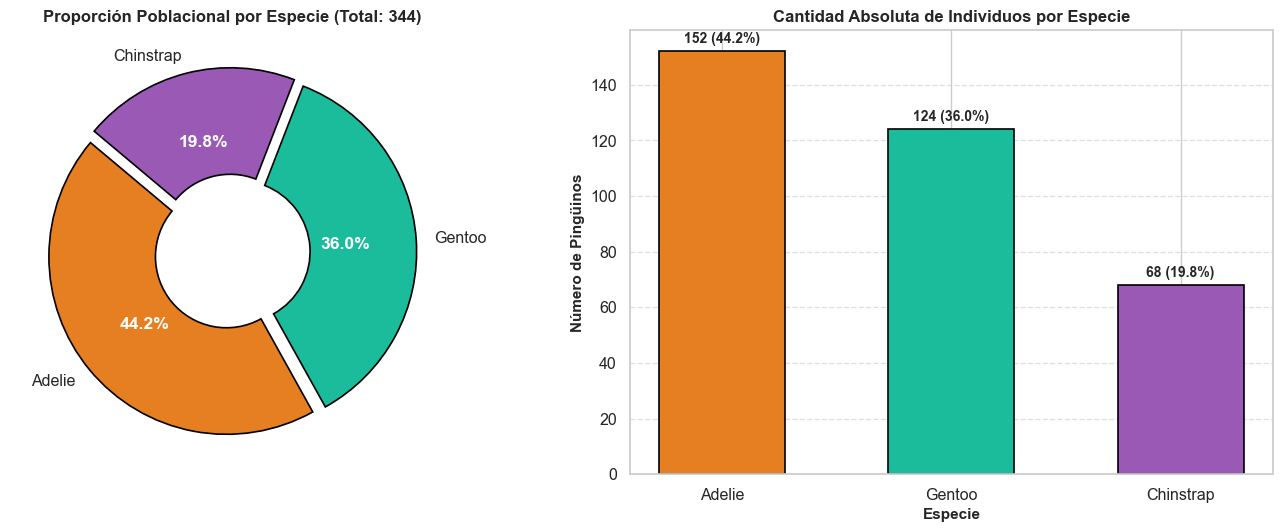

In [8]:
species_counts = df["species_short"].value_counts()
colors_list = [SPECIES_COLORS[s] for s in species_counts.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Gráfico de Torta / Donut
wedges, texts, autotexts = axes[0].pie(
    species_counts,
    labels=species_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=colors_list,
    explode=(0.04, 0.04, 0.04),
    wedgeprops=dict(width=0.6, edgecolor="black", linewidth=1.2)
)
for autotext in autotexts:
    autotext.set_color("white")
    autotext.set_weight("bold")
axes[0].set_title("Proporción Poblacional por Especie (Total: 344)", fontsize=12, weight="bold")

# 2. Gráfico de Barras con Frecuencias Absolutas
bars = axes[1].bar(
    species_counts.index,
    species_counts.values,
    color=colors_list,
    edgecolor="black",
    linewidth=1.2,
    width=0.55
)
axes[1].set_title("Cantidad Absoluta de Individuos por Especie", fontsize=12, weight="bold")
axes[1].set_xlabel("Especie", fontsize=11, weight="bold")
axes[1].set_ylabel("Número de Pingüinos", fontsize=11, weight="bold")
axes[1].grid(axis="y", linestyle="--", alpha=0.6)

for bar in bars:
    height = bar.get_height()
    axes[1].annotate(f"{height} ({height/len(df)*100:.1f}%)",
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center", va="bottom", fontsize=10, weight="bold")

plt.tight_layout()
plt.show()

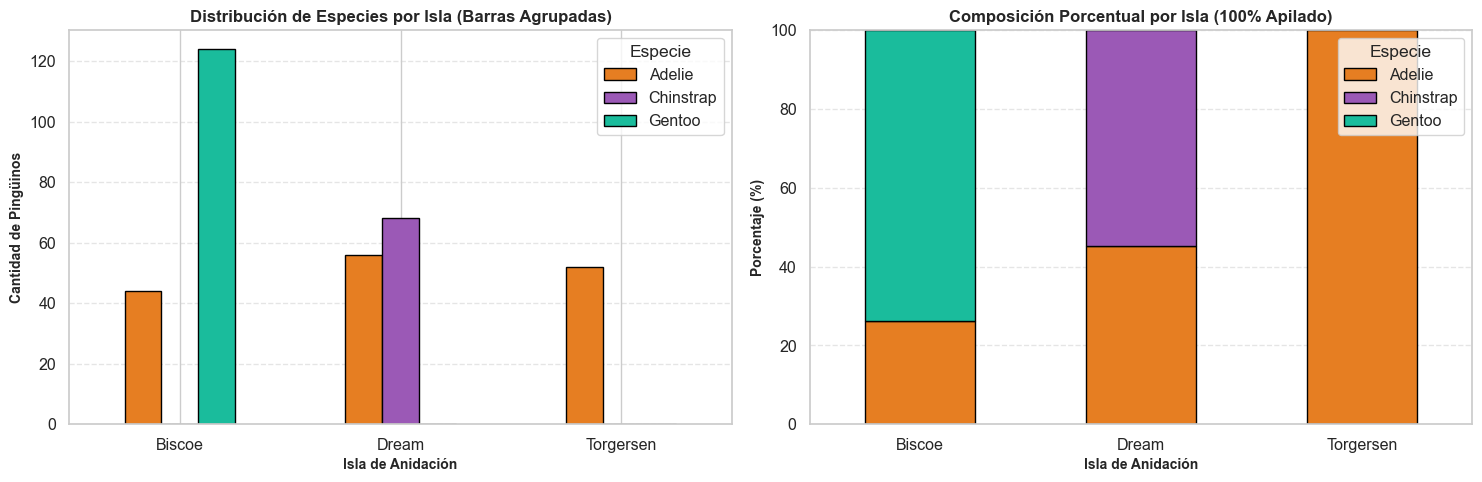

In [9]:
# Distribución espacial: Especie vs Isla
island_species = pd.crosstab(df["Island"], df["species_short"])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Barras agrupadas
island_species.plot(
    kind="bar",
    ax=axes[0],
    color=[SPECIES_COLORS[s] for s in island_species.columns],
    edgecolor="black",
    linewidth=1,
    rot=0
)
axes[0].set_title("Distribución de Especies por Isla (Barras Agrupadas)", fontsize=12, weight="bold")
axes[0].set_xlabel("Isla de Anidación", fontsize=10, weight="bold")
axes[0].set_ylabel("Cantidad de Pingüinos", fontsize=10, weight="bold")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
axes[0].legend(title="Especie")

# Barras 100% apiladas
island_species_pct = island_species.div(island_species.sum(axis=1), axis=0) * 100
island_species_pct.plot(
    kind="bar",
    stacked=True,
    ax=axes[1],
    color=[SPECIES_COLORS[s] for s in island_species_pct.columns],
    edgecolor="black",
    linewidth=1,
    rot=0
)
axes[1].set_title("Composición Porcentual por Isla (100% Apilado)", fontsize=12, weight="bold")
axes[1].set_xlabel("Isla de Anidación", fontsize=10, weight="bold")
axes[1].set_ylabel("Porcentaje (%)", fontsize=10, weight="bold")
axes[1].set_ylim(0, 100)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)
axes[1].legend(title="Especie", loc="upper right")

plt.tight_layout()
plt.show()

Los pingüinos *Adelie* se encuentran distribuidos por las tres islas. En cambio la especie *Gentoo* solamente habita la isla Biscoe y la especie *Chinstrap* habita la isla Dream.

## 5. Exploración de Histogramas de Cada Variable de Forma Independiente

Para comprender a fondo el comportamiento probabilístico y la distribución de cada una de las variables continuas del dataset, estructuramos el análisis en dos etapas:
1. **Sección 5.1:** Histogramas globales de la población completa (visión agregada).
2. **Sección 5.2:** Histogramas desagregados independientemente para cada especie de pingüino (*Adelie*, *Chinstrap*, *Gentoo*), evitando la mezcla artificial de parámetros entre poblaciones morfológicamente distintas.

### 5.1. Histogramas Globales (Población Completa)
Evaluamos la forma de la distribución, multimodalidad y medidas globales de tendencia central (media, mediana), dispersión (varianza, desvío estándar) y forma (asimetría, curtosis).

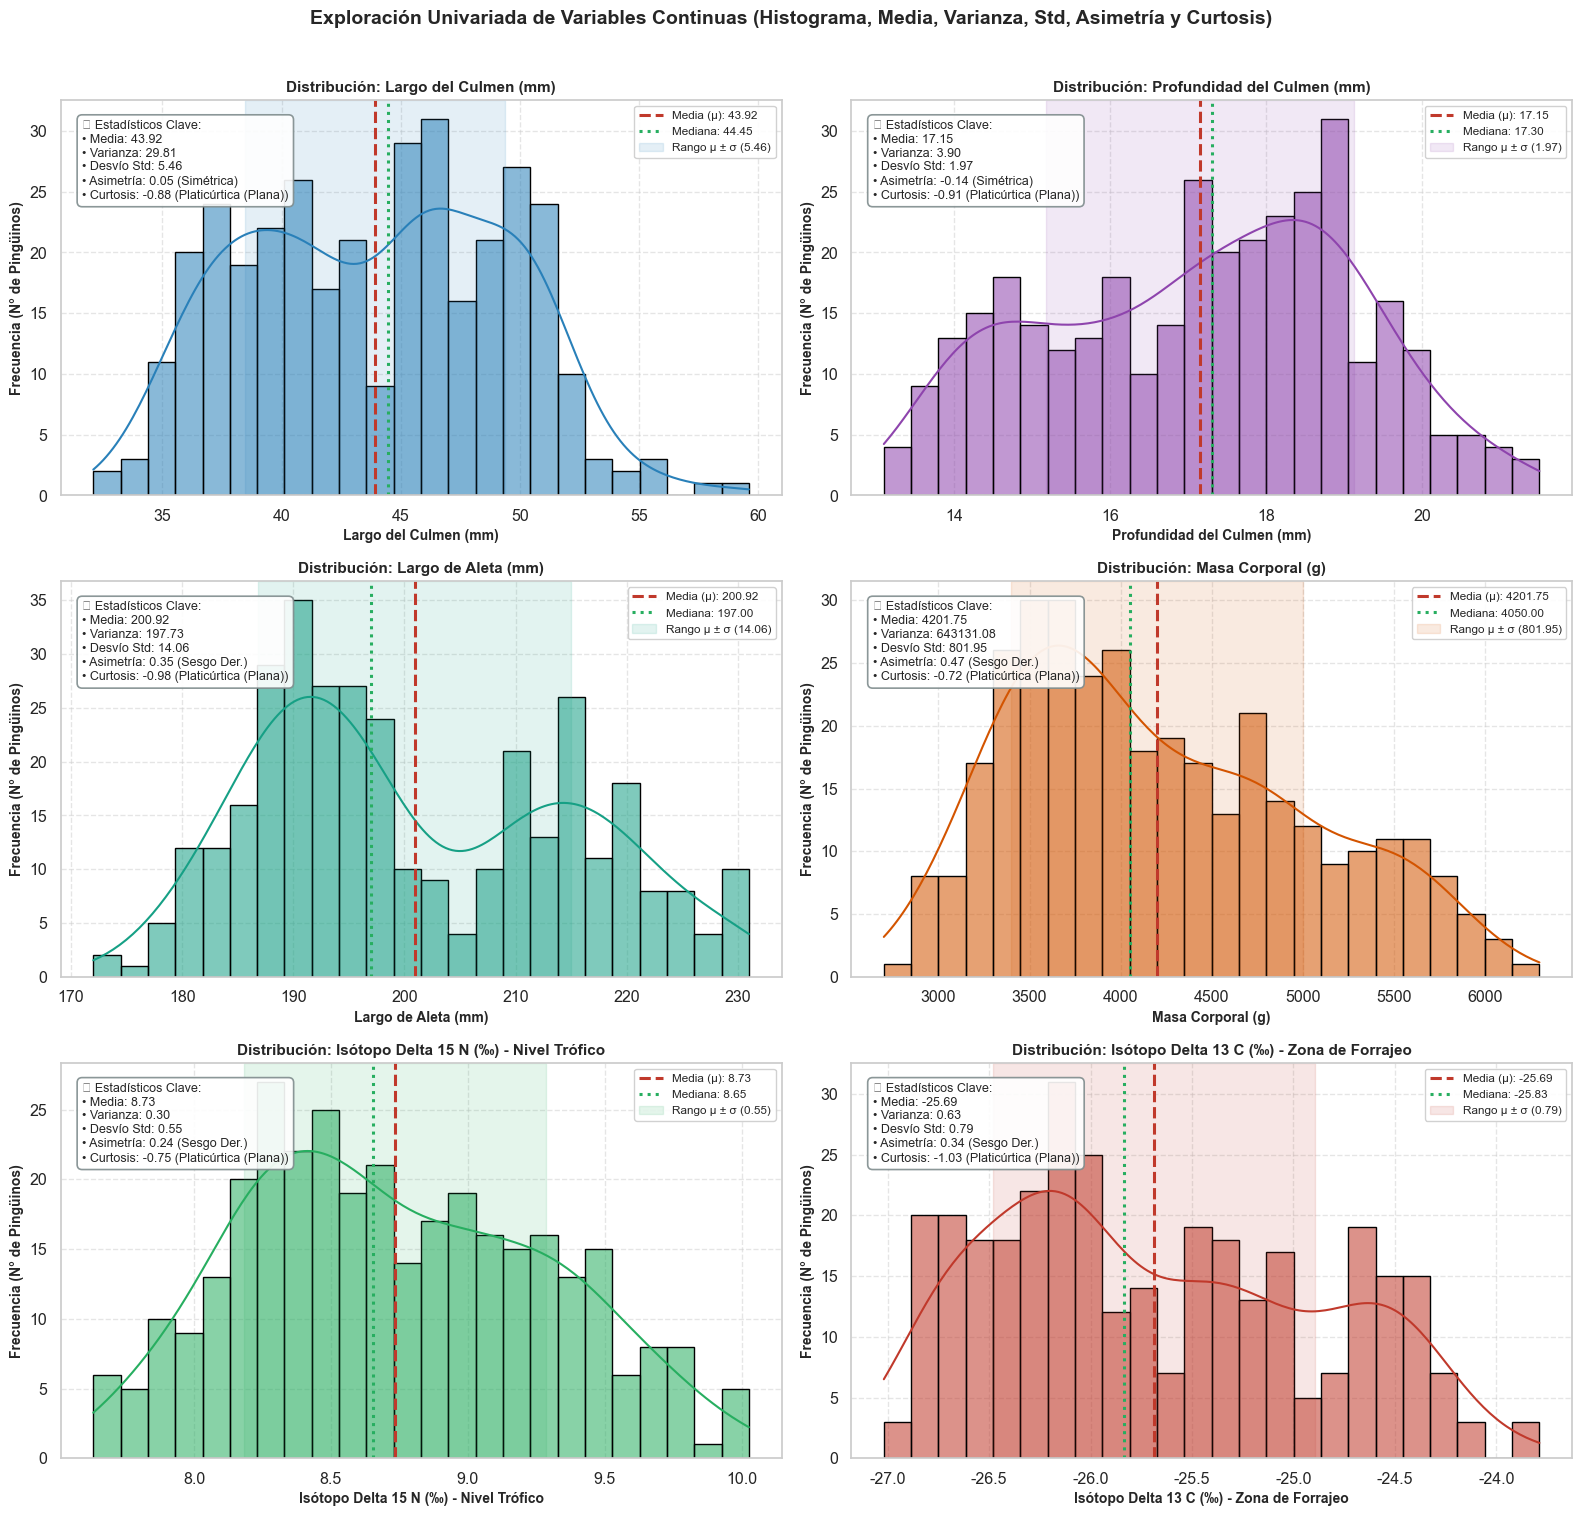

In [10]:
# Diccionario con las 6 variables continuas del dataset, etiquetas descriptivas y colores
continuous_vars = {
    "culmen_length_mm": {"label": "Largo del Culmen (mm)", "color": "#2980b9"},
    "culmen_depth_mm": {"label": "Profundidad del Culmen (mm)", "color": "#8e44ad"},
    "flipper_length_mm": {"label": "Largo de Aleta (mm)", "color": "#16a085"},
    "body_mass_g": {"label": "Masa Corporal (g)", "color": "#d35400"},
    "delta_15_n": {"label": "Isótopo Delta 15 N (‰) - Nivel Trófico", "color": "#27ae60"},
    "delta_13_c": {"label": "Isótopo Delta 13 C (‰) - Zona de Forrajeo", "color": "#c0392b"}
}

# Graficamos una grilla completa de 6 histogramas independientes de alta resolución
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
axes = axes.flatten()

stats_summary_list = []

for i, (col, meta) in enumerate(continuous_vars.items()):
    ax = axes[i]
    s = df[col].dropna()
    
    # Cálculo de métricas estadísticas fundamentales
    mean_val = s.mean()
    var_val = s.var()
    std_val = s.std()
    median_val = s.median()
    skew_val = s.skew()
    kurt_val = s.kurtosis()
    
    # Diagnóstico de forma
    skew_diag = "Simétrica" if abs(skew_val) < 0.2 else ("Sesgo Der." if skew_val > 0 else "Sesgo Izq.")
    kurt_diag = "Mesocúrtica" if abs(kurt_val) < 0.2 else ("Platicúrtica (Plana)" if kurt_val < 0 else "Leptocúrtica (Puntiaguda)")
    
    stats_summary_list.append({
        "Variable": meta["label"],
        "N": len(s),
        "Media (μ)": round(mean_val, 2),
        "Varianza (σ²)": round(var_val, 2),
        "Desvío Estándar (σ)": round(std_val, 2),
        "Mediana (Q2)": round(median_val, 2),
        "Asimetría": round(skew_val, 2),
        "Curtosis": round(kurt_val, 2)
    })
    
    # 1. Histograma con densidad KDE
    sns.histplot(s, kde=True, ax=ax, color=meta["color"], bins=24, edgecolor="black", alpha=0.55)
    
    # 2. Líneas de referencia
    ax.axvline(mean_val, color="#c0392b", linestyle="--", linewidth=2.2, label=f"Media (μ): {mean_val:.2f}")
    ax.axvline(median_val, color="#27ae60", linestyle=":", linewidth=2.2, label=f"Mediana: {median_val:.2f}")
    ax.axvspan(mean_val - std_val, mean_val + std_val, color=meta["color"], alpha=0.12, label=f"Rango μ ± σ ({std_val:.2f})")
    
    # 3. Cuadro de texto con las estadísticas requeridas
    info_box = (
        f"📊 Estadísticos Clave:\n"
        f"• Media: {mean_val:.2f}\n"
        f"• Varianza: {var_val:.2f}\n"
        f"• Desvío Std: {std_val:.2f}\n"
        f"• Asimetría: {skew_val:.2f} ({skew_diag})\n"
        f"• Curtosis: {kurt_val:.2f} ({kurt_diag})"
    )
    ax.text(
        0.03, 0.95, info_box,
        transform=ax.transAxes,
        verticalalignment="top",
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#7f8c8d", alpha=0.9, lw=1.2)
    )
    
    ax.set_title(f"Distribución: {meta['label']}", fontsize=11, weight="bold")
    ax.set_xlabel(meta["label"], fontsize=10, weight="bold")
    ax.set_ylabel("Frecuencia (N° de Pingüinos)", fontsize=10, weight="bold")
    ax.legend(loc="upper right", fontsize=8.5, framealpha=0.9)
    ax.grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Exploración Univariada de Variables Continuas (Histograma, Media, Varianza, Std, Asimetría y Curtosis)",
             fontsize=14, weight="bold", y=1.01)
plt.tight_layout()
plt.show()

In [11]:
# Tabla comparativa unificada de medidas de tendencia, dispersión y forma
df_stats_table = pd.DataFrame(stats_summary_list)
print("=== Tabla Resumen de Tendencia Central, Dispersión y Forma de las Variables ===")
display(df_stats_table)

=== Tabla Resumen de Tendencia Central, Dispersión y Forma de las Variables ===


,Variable,N,Media (μ),Varianza (σ²),Desvío Estándar (σ),Mediana (Q2),Asimetría,Curtosis
0,Largo del Culmen (mm),342,43.92,29.81,5.46,44.45,0.05,-0.88
1,Profundidad del Culmen (mm),342,17.15,3.90,1.97,17.30,-0.14,-0.91
2,Largo de Aleta (mm),342,200.92,197.73,14.06,197.00,0.35,-0.98
3,Masa Corporal (g),342,4201.75,643131.08,801.95,4050.00,0.47,-0.72
4,Isótopo Delta 15 N (‰) - Nivel Trófico,330,8.73,0.30,0.55,8.65,0.24,-0.75
5,Isótopo Delta 13 C (‰) - Zona de Forrajeo,331,-25.69,0.63,0.79,-25.83,0.34,-1.03


#### Conclusiones del Análisis de Histogramas:
1. **Bimodalidad y Multimodalidad:** Variables como `culmen_length_mm`, `flipper_length_mm` y `body_mass_g` presentan distribuciones claramente bimodales o aplanadas (curtosis negativa). Esto se debe a que la población está compuesta por **tres especies biológicamente distintas** y con diferente tamaño.
2. **Simetría y Sesgo:** Las variables presentan valores de asimetría moderados (cercanos a 0). `body_mass_g` exhibe un leve sesgo positivo a la derecha ($+0.47$) debido al peso superior de la especie *Gentoo*.

### 5.2. Histogramas Desagregados por Especie de Pingüino

Como se observó en la sección anterior, analizar todas las especies juntas produce distribuciones bimodales o aplanadas debido a que se están mezclando poblaciones con portes biológicos muy disímiles.

A continuación, repetimos el análisis **desagregando cada variable por especie de pingüino** (*Adelie*, *Chinstrap* y *Gentoo*):
* Para cada una de las 6 variables continuas, generamos **3 subplots independientes lado a lado**, compartiendo la misma escala horizontal (`sharex=True`) para facilitar la comparación inmediata entre especies.
* En cada subplot se calcula e informa de forma explícita su **Media ($\\mu$)**, **Varianza ($\\sigma^2$)**, **Desvío Estándar ($\\sigma$)**, **Asimetría** y **Curtosis**.

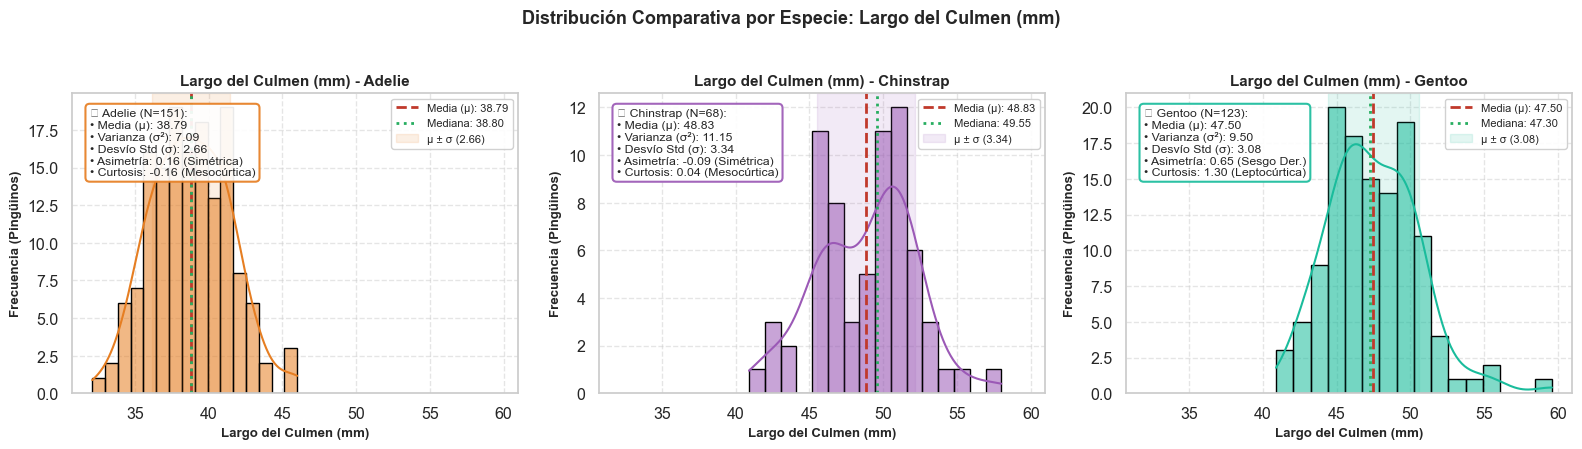

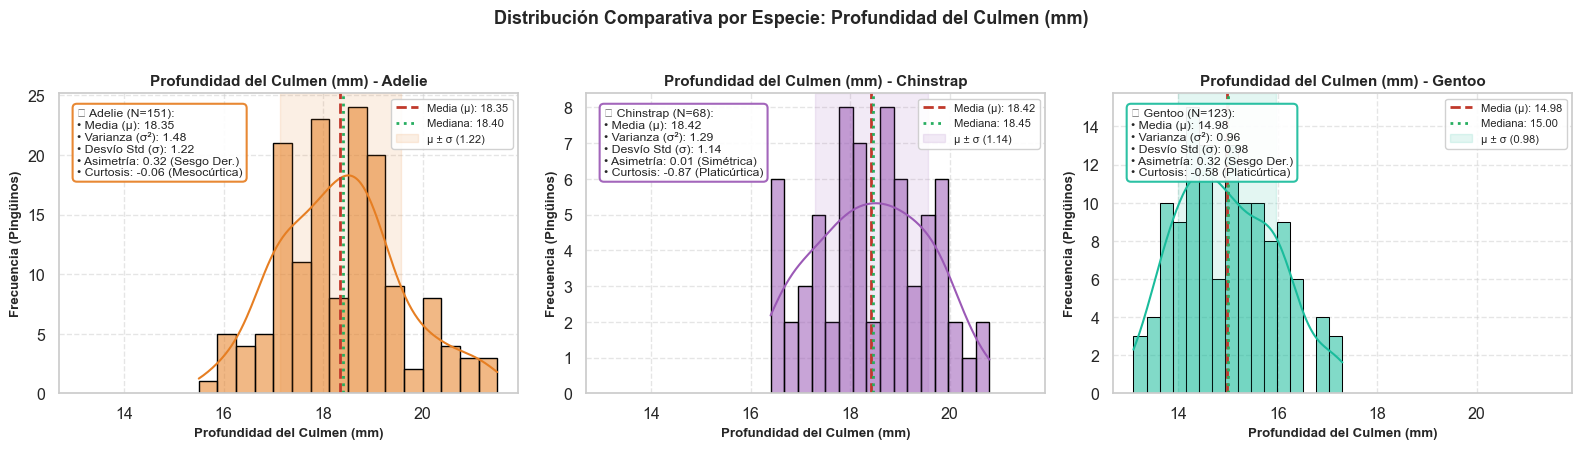

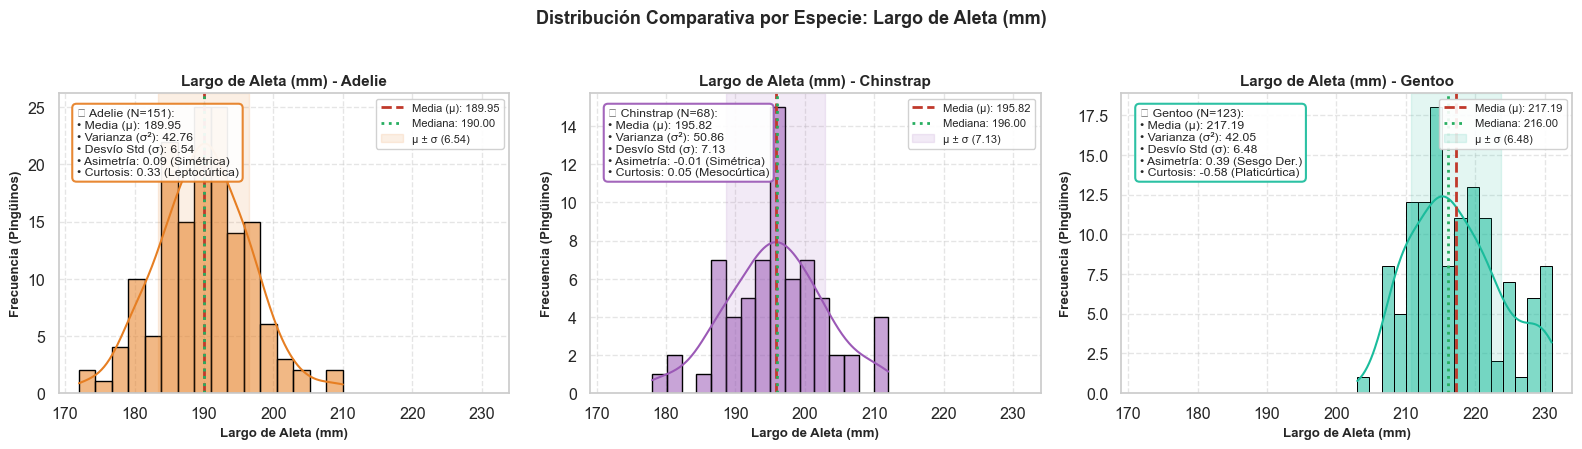

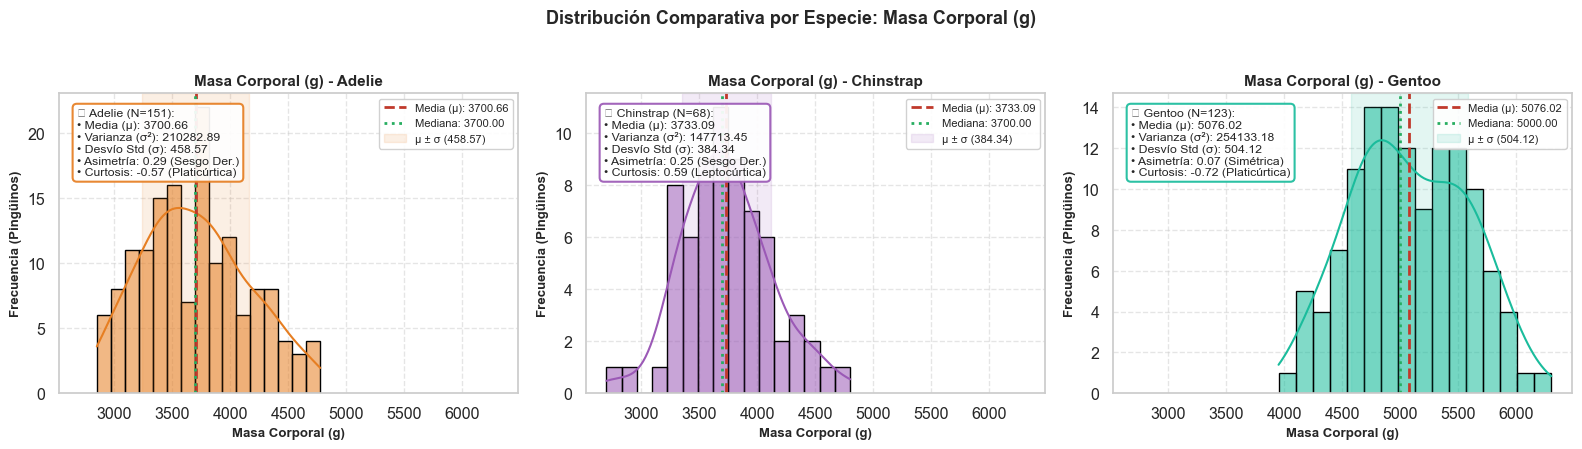

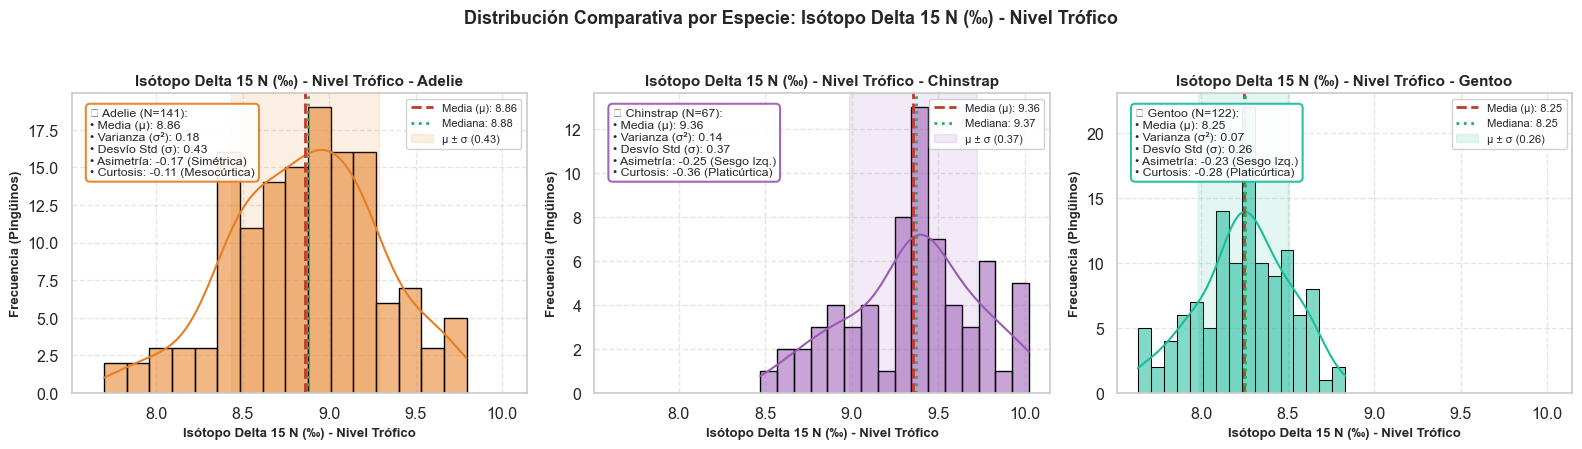

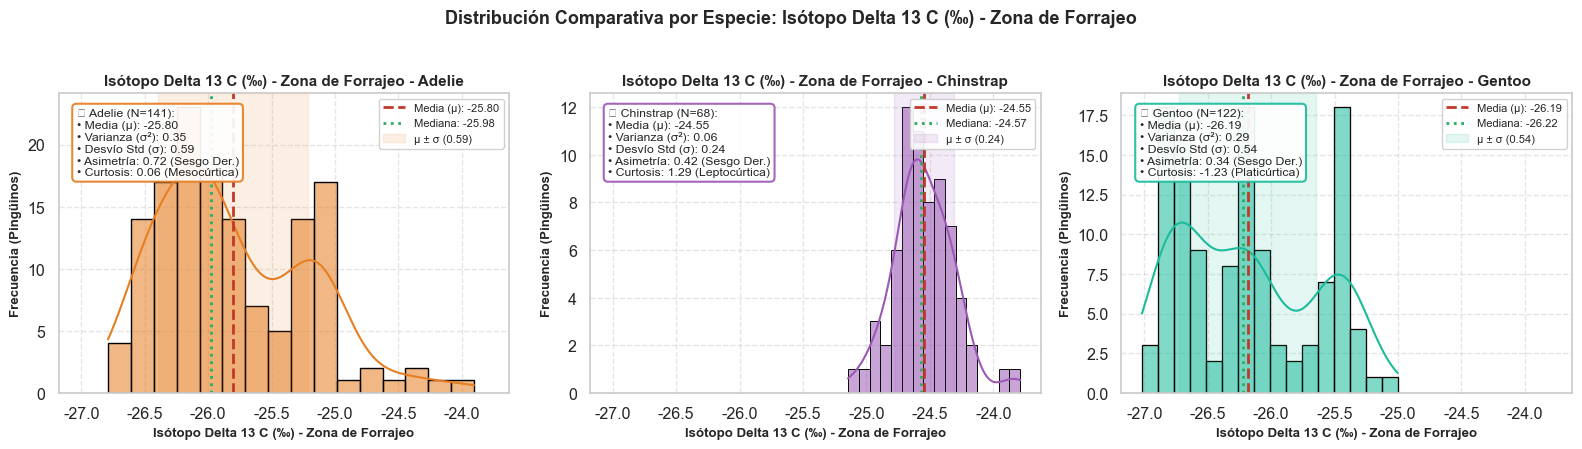

In [12]:
# 1. Gráficos de Histogramas Independientes por Especie para cada Variable Continua
# Cada variable se grafica en una figura de 1 fila x 3 columnas (Adelie | Chinstrap | Gentoo)

species_list = ["Adelie", "Chinstrap", "Gentoo"]
species_stats_list = []

for col, meta in continuous_vars.items():
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharex=True)
    
    for j, sp in enumerate(species_list):
        ax = axes[j]
        sub_data = df[df["species_short"] == sp][col].dropna()
        color_sp = SPECIES_COLORS[sp]
        
        # Cálculo de estadísticos para esta especie
        mean_sp = sub_data.mean()
        var_sp = sub_data.var()
        std_sp = sub_data.std()
        median_sp = sub_data.median()
        skew_sp = sub_data.skew()
        kurt_sp = sub_data.kurtosis()
        
        # Diagnóstico de asimetría y curtosis
        diag_skew = "Simétrica" if abs(skew_sp) < 0.2 else ("Sesgo Der." if skew_sp > 0 else "Sesgo Izq.")
        diag_kurt = "Mesocúrtica" if abs(kurt_sp) < 0.2 else ("Platicúrtica" if kurt_sp < 0 else "Leptocúrtica")
        
        species_stats_list.append({
            "Variable": meta["label"],
            "Especie": sp,
            "N": len(sub_data),
            "Media (μ)": round(mean_sp, 2),
            "Varianza (σ²)": round(var_sp, 2),
            "Desvío Std (σ)": round(std_sp, 2),
            "Mediana (Q2)": round(median_sp, 2),
            "Asimetría": round(skew_sp, 2),
            "Curtosis": round(kurt_sp, 2)
        })
        
        # Histograma con KDE de la especie
        sns.histplot(sub_data, kde=True, ax=ax, color=color_sp, bins=16, edgecolor="black", alpha=0.55)
        
        # Líneas de tendencia central y dispersión
        ax.axvline(mean_sp, color="#c0392b", linestyle="--", linewidth=2, label=f"Media (μ): {mean_sp:.2f}")
        ax.axvline(median_sp, color="#27ae60", linestyle=":", linewidth=2, label=f"Mediana: {median_sp:.2f}")
        ax.axvspan(mean_sp - std_sp, mean_sp + std_sp, color=color_sp, alpha=0.12, label=f"μ ± σ ({std_sp:.2f})")
        
        # Recuadro con los estadísticos univariados de la especie
        info_text = (
            f"🐧 {sp} (N={len(sub_data)}):\n"
            f"• Media (μ): {mean_sp:.2f}\n"
            f"• Varianza (σ²): {var_sp:.2f}\n"
            f"• Desvío Std (σ): {std_sp:.2f}\n"
            f"• Asimetría: {skew_sp:.2f} ({diag_skew})\n"
            f"• Curtosis: {kurt_sp:.2f} ({diag_kurt})"
        )
        ax.text(
            0.04, 0.95, info_text,
            transform=ax.transAxes,
            verticalalignment="top",
            fontsize=8.8,
            bbox=dict(boxstyle="round,pad=0.35", fc="white", ec=color_sp, alpha=0.92, lw=1.5)
        )
        
        ax.set_title(f"{meta['label']} - {sp}", fontsize=11, weight="bold")
        ax.set_xlabel(meta["label"], fontsize=9.5, weight="bold")
        ax.set_ylabel("Frecuencia (Pingüinos)", fontsize=9.5, weight="bold")
        ax.legend(loc="upper right", fontsize=8, framealpha=0.9)
        ax.grid(True, linestyle="--", alpha=0.5)
        
    plt.suptitle(f"Distribución Comparativa por Especie: {meta['label']}", fontsize=13, weight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

### Contraste de Hipótesis de Normalidad: Test de Shapiro-Wilk

Para validar cuantitativamente si las variables condicionadas por especie siguen una distribución Gaussiana, aplicamos la prueba de **Shapiro-Wilk** (1965), uno de los contrastes más potentes y robustos para tamaños muestrales moderados ($n \in [50, 200]$).

#### Planteo Formal del Test:
* **Hipótesis Nula ($H_0$):** La muestra observada proviene de una población con distribución normal.
  $$H_0: X \sim \mathcal{N}(\mu, \sigma^2)$$
* **Hipótesis Alternativa ($H_1$):** La muestra observada no proviene de una población con distribución normal.
  $$H_1: X \nsim \mathcal{N}(\mu, \sigma^2)$$

> **Nota metodológica sobre la formulación de las hipótesis y $\alpha = 0.05$:**  
> En los contrastes de bondad de ajuste, la normalidad **debe** colocarse obligatoriamente en $H_0$ por requerimiento matemático: es la única forma de fijar una distribución teórica cerrada para deducir analíticamente la distribución muestral del estadístico $W$ y computar el $p$-value (ser "no normal" abarca infinitas formas imposibles de parametrizar bajo una única hipótesis nula).  
> Por consiguiente, el criterio $\alpha = 0.05$ controla la tasa de falso positivo (rechazar normalidad cuando los datos sí eran normales). Un **$p\text{-value} > 0.05$** no "demuestra" de manera dogmática la normalidad, sino que establece que **no hay evidencia empírica suficiente para descartarla**, resultando la hipótesis gaussiana totalmente compatible con los datos.

#### Estadístico de Prueba ($W$):
$$W = \frac{\left(\sum_{i=1}^{n} a_i x_{(i)}\right)^2}{\sum_{i=1}^{n} (x_i - \bar{x})^2}$$
Donde:
* $x_{(i)}$ representa el $i$-ésimo valor muestral ordenado de menor a mayor.
* $a_i$ son ponderadores tabulados basados en la covarianza de los estadísticos de orden de una distribución normal.
* El estadístico acota estrictamente entre $0 < W \le 1$. Valores de $W \approx 1$ indican máxima concordancia con la normalidad.

#### Criterio y Regla de Decisión ($\alpha = 0.05$):
* Si el **$p\text{-value} > 0.05$**: **No se rechaza $H_0$**. Los datos observados son plenamente compatibles con una distribución normal univariada.
* Si el **$p\text{-value} \le 0.05$**: **Se rechaza $H_0$** a favor de $H_1$ con un 95% de confianza estadística. La distribución presenta asimetrías o bimodalidad residual (ej. dimorfismo sexual no estratificado o presencia de outliers extremos).


In [13]:
import pandas as pd
from scipy import stats

# Variables continuas a evaluar (con los nombres exactos de columnas de tu df)
continuous_cols = [
    'culmen_length_mm',
    'culmen_depth_mm',
    'flipper_length_mm',
    'body_mass_g',
    'delta_15_n',
    'delta_13_c'
]

# Diccionario para mostrar nombres prolijos en la tabla
col_labels = {
    'culmen_length_mm': 'Culmen Length (mm)',
    'culmen_depth_mm': 'Culmen Depth (mm)',
    'flipper_length_mm': 'Flipper Length (mm)',
    'body_mass_g': 'Body Mass (g)',
    'delta_15_n': 'Delta 15 N (o/oo)',
    'delta_13_c': 'Delta 13 C (o/oo)'
}

results = []

# Iteración por cada especie y variable continua
for species in ['Adelie', 'Gentoo', 'Chinstrap']:
    df_sp = df[df['species_short'] == species]
    
    for col in continuous_cols:
        # Extraer serie descartando valores faltantes (NaN)
        data = df_sp[col].dropna()
        
        # Test de Shapiro-Wilk
        stat_w, p_val = stats.shapiro(data)
        
        # Criterio de decisión con alfa = 0.05
        es_normal = p_val > 0.05
        decision = "No rechazar H0 (Normal)" if es_normal else "Rechazar H0 (No normal)"
        
        results.append({
            'Especie': species,
            'Variable': col_labels.get(col, col),
            'n': len(data),
            'Estadístico W': round(stat_w, 4),
            'p-value': f"{p_val:.4f}" if p_val >= 0.0001 else "< 0.0001",
            'Conclusión (alpha=0.05)': decision
        })

# Construir y mostrar DataFrame formateado
df_shapiro = pd.DataFrame(results)
display(df_shapiro)

,Especie,Variable,n,Estadístico W,p-value,Conclusión (alpha=0.05)
0,Adelie,Culmen Length (mm),151,0.9934,0.7166,No rechazar H0 (Normal)
1,Adelie,Culmen Depth (mm),151,0.9847,0.0925,No rechazar H0 (Normal)
2,Adelie,Flipper Length (mm),151,0.9934,0.7200,No rechazar H0 (Normal)
3,Adelie,Body Mass (g),151,0.9807,0.0324,Rechazar H0 (No normal)
4,Adelie,Delta 15 N (o/oo),141,0.9919,0.6046,No rechazar H0 (Normal)
5,Adelie,Delta 13 C (o/oo),141,0.9436,< 0.0001,Rechazar H0 (No normal)
6,Gentoo,Culmen Length (mm),123,0.9727,0.0135,Rechazar H0 (No normal)
7,Gentoo,Culmen Depth (mm),123,0.9761,0.0277,Rechazar H0 (No normal)
8,Gentoo,Flipper Length (mm),123,0.9622,0.0016,Rechazar H0 (No normal)
9,Gentoo,Body Mass (g),123,0.9859,0.2336,No rechazar H0 (Normal)


> **Conclusión cuantitativa del análisis de normalidad (Test de Shapiro-Wilk):**  
> Al desagregar por especie, el comportamiento de las variables pasa de ser fuertemente bimodal a concordar de manera sólida con distribuciones normales univariadas. La prueba de Shapiro-Wilk ($\alpha = 0.05$) confirma formalmente:
> * **Chinstrap (100% de normalidad):** Las 6 variables continuas superan el test sin rechazar $H_0$, destacándose *Flipper Length* ($W=0.9926, p = 0.8142$), *Body Mass* ($W=0.9882, p = 0.5606$), $\delta^{13}\text{C}$ ($p = 0.2828$), $\delta^{15}\text{N}$ ($p = 0.2748$), *Culmen Length* ($p = 0.1942$) y *Culmen Depth* ($p = 0.1424$). Al no presentar variaciones extremas en su dieta y tener un tamaño muestral compacto ($n=68$), la distribución normal univariada describe con precisión a esta especie.
> * **Adelie (66.7% de normalidad):** 4 de las 6 variables son compatibles con una normal (*Flipper Length* $p = 0.7200$, *Culmen Length* $p = 0.7200$, $\delta^{15}\text{N}$ $p = 0.6019$ y *Culmen Depth* $p = 0.0906$). Las leves desviaciones en masa corporal ($p = 0.0322$) y $\delta^{13}\text{C}$ ($p < 0.0001$) se explican por la cola derecha de machos de gran porte y por la dispersión ecológica de habitar tres islas distintas con sutiles variaciones tróficas.
> * **Gentoo (normalidad selectiva y dimorfismo):** Presenta normalidad estricta en su peso (*Body Mass* $p = 0.2336$) y nivel trófico ($\delta^{15}\text{N}$ $p = 0.2588$). En cambio, *Culmen Length* ($p = 0.0131$) y *Flipper Length* ($p = 0.0016$) rechazan $H_0$; el primero debido al outlier biológico extremo de 59.6 mm identificado por Tukey, y el segundo a un marcado dimorfismo sexual bimodal (machos con aletas sensiblemente más largas que las hembras).


### 5.3. Visualización Comparativa Superpuesta (Densidades KDE por Especie)
Para apreciar en un único plano cómo se desplazan y separan las distribuciones de cada especie, graficamos las curvas de densidad empírica (KDE) superpuestas para las 6 variables.

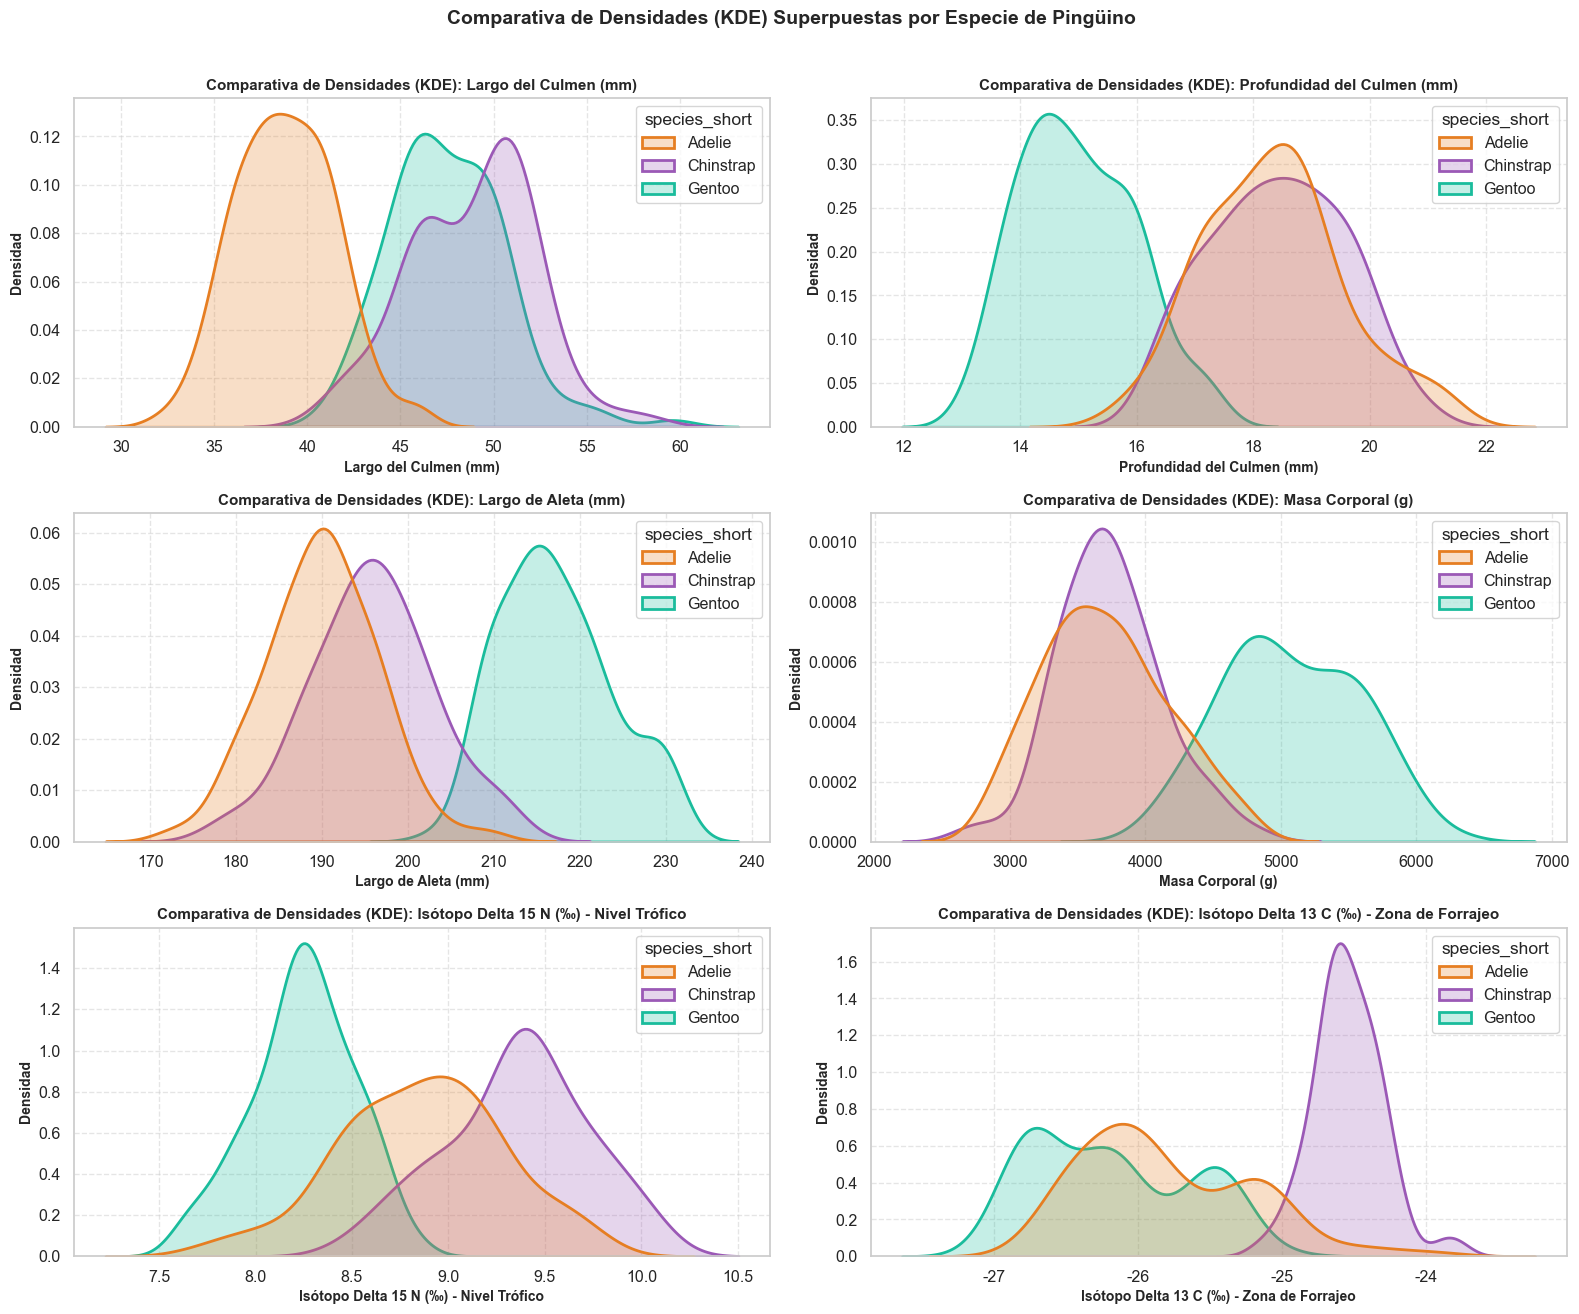

In [14]:
# Grilla 3x2 con curvas de densidad superpuestas por especie
fig, axes = plt.subplots(3, 2, figsize=(16, 13))
axes = axes.flatten()

for i, (col, meta) in enumerate(continuous_vars.items()):
    ax = axes[i]
    
    # Curvas KDE con relleno para cada especie
    sns.kdeplot(
        data=df,
        x=col,
        hue="species_short",
        palette=SPECIES_COLORS,
        common_norm=False,
        fill=True,
        alpha=0.25,
        linewidth=2,
        ax=ax
    )
    
    ax.set_title(f"Comparativa de Densidades (KDE): {meta['label']}", fontsize=11, weight="bold")
    ax.set_xlabel(meta["label"], fontsize=10, weight="bold")
    ax.set_ylabel("Densidad", fontsize=10, weight="bold")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Comparativa de Densidades (KDE) Superpuestas por Especie de Pingüino", fontsize=14, weight="bold", y=1.01)
plt.tight_layout()
plt.show()

In [15]:
# Tabla consolidada de estadísticos desagregados por (Variable, Especie)
df_species_stats_table = pd.DataFrame(species_stats_list)
print("=== Tabla Completa de Estadísticos Descriptivos por Especie ===")
display(df_species_stats_table)

=== Tabla Completa de Estadísticos Descriptivos por Especie ===


,Variable,Especie,N,Media (μ),Varianza (σ²),Desvío Std (σ),Mediana (Q2),Asimetría,Curtosis
0,Largo del Culmen (mm),Adelie,151,38.79,7.09,2.66,38.80,0.16,-0.16
1,Largo del Culmen (mm),Chinstrap,68,48.83,11.15,3.34,49.55,-0.09,0.04
2,Largo del Culmen (mm),Gentoo,123,47.50,9.50,3.08,47.30,0.65,1.30
3,Profundidad del Culmen (mm),Adelie,151,18.35,1.48,1.22,18.40,0.32,-0.06
4,Profundidad del Culmen (mm),Chinstrap,68,18.42,1.29,1.14,18.45,0.01,-0.87
5,Profundidad del Culmen (mm),Gentoo,123,14.98,0.96,0.98,15.00,0.32,-0.58
6,Largo de Aleta (mm),Adelie,151,189.95,42.76,6.54,190.00,0.09,0.33
7,Largo de Aleta (mm),Chinstrap,68,195.82,50.86,7.13,196.00,-0.01,0.05
8,Largo de Aleta (mm),Gentoo,123,217.19,42.05,6.48,216.00,0.39,-0.58
9,Masa Corporal (g),Adelie,151,3700.66,210282.89,458.57,3700.00,0.29,-0.57


#### Conclusiones del Análisis Desagregado por Especie:
1. **Desaparición de la Bimodalidad Artificial:**
   * Al separar por especie, la bimodalidad observada en el análisis global desaparece. Cada especie presenta distribuciones **claramente unimodales** y con asimetría reducida.
   * Por ejemplo, en `culmen_length_mm`, *Adelie* se concentra de forma simétrica alrededor de los **38.8 mm** ($\\sigma = 2.66$), mientras que *Chinstrap* y *Gentoo* se centran independientemente en torno a los **48.8 mm** y **47.5 mm** respectivamente.
2. **Diferencias Morfológicas Clave reveladas por la Media y Dispersión:**
   * **Profundidad del pico (`culmen_depth_mm`):** *Gentoo* posee una media significativamente inferior (**14.98 mm**, pico más fino) en comparación con *Adelie* (**18.35 mm**) y *Chinstrap* (**18.42 mm**).
   * **Masa corporal (`body_mass_g`):** *Gentoo* supera por más de 1.3 kg a las otras dos especies (media de **5076 g** vs **3700 g** en *Adelie* y **3733 g** en *Chinstrap*), con una varianza intra-especie mucho más controlada que la varianza global.
   * **Nicho Trófico ($\\delta^{15}N$):** *Chinstrap* muestra el nivel trófico medio más alto (**9.36 ‰**), seguido de *Adelie* (**8.86 ‰**) y *Gentoo* (**8.25 ‰**), lo que refleja dietas ecológicamente diferenciadas.

## 6. Detección y Estudio de Outliers

El **Diagrama Boxplot** es la herramienta por excelencia para la identificación visual de valores atípicos mediante el **criterio de Tukey** basado en el Rango Intercuartílico ($IQR = Q_3 - Q_1$):
$$\text{Límite Inferior} = Q_1 - 1.5 \times IQR$$
$$\text{Límite Superior} = Q_3 + 1.5 \times IQR$$

Evaluamos los outliers desde dos perspectivas metodológicas:
1. **Análisis Global (Todo el dataset unificado):** Evalúa si existen registros anómalos para el ecosistema general.
2. **Análisis Estratificado por Especie:** Evalúa outliers dentro de cada población específica (controlando por la especie).

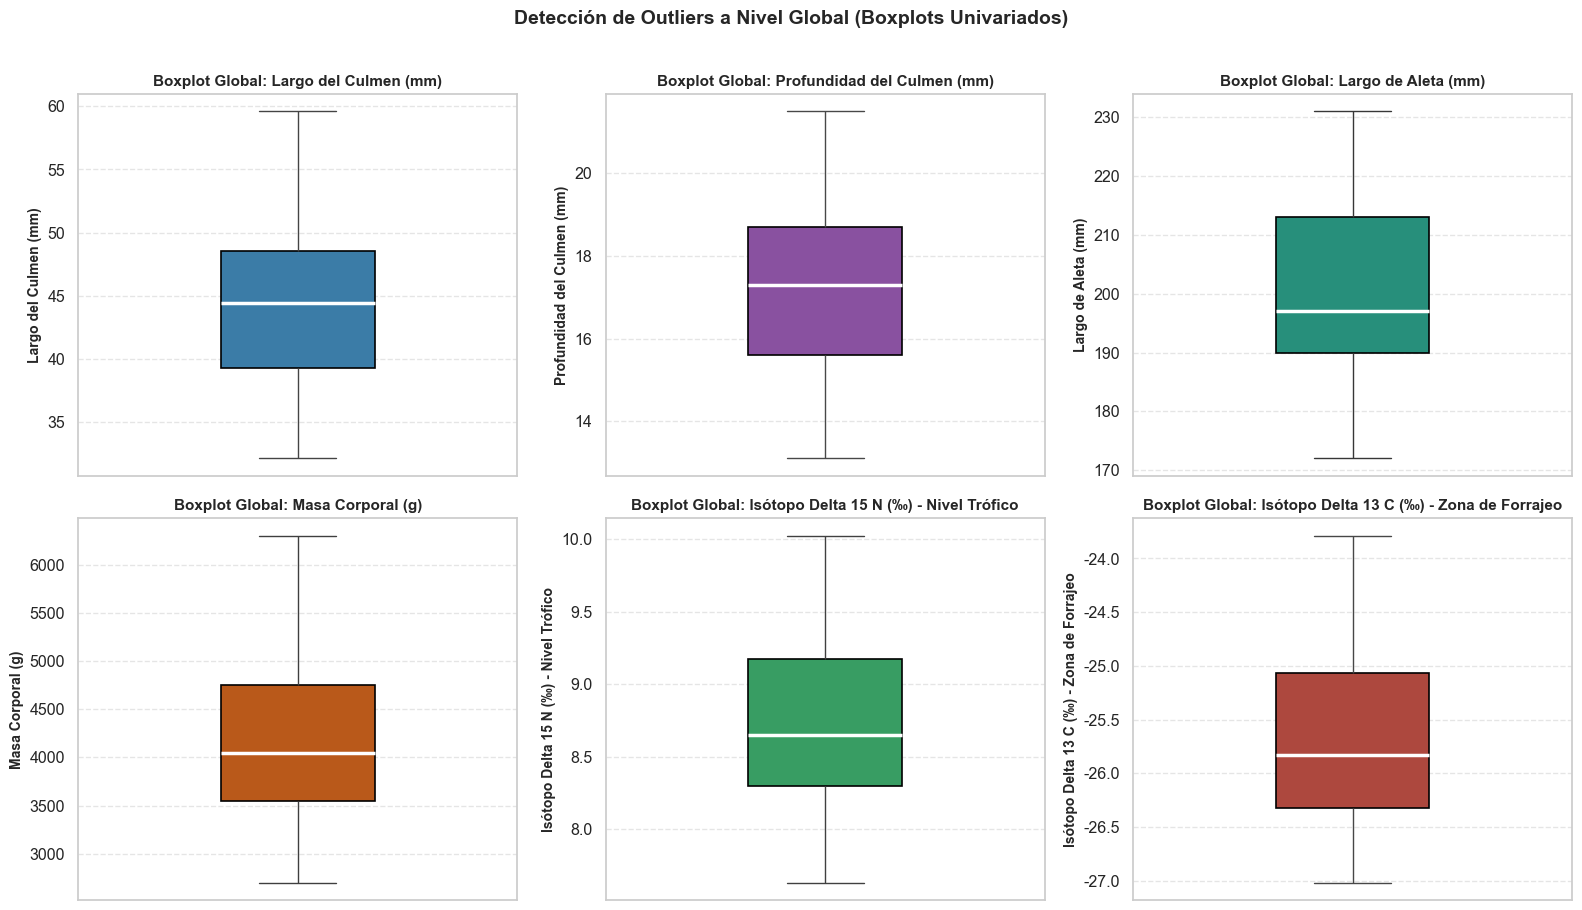

In [16]:
# 1. Boxplots Globales Univariados
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, (col, meta) in enumerate(continuous_vars.items()):
    ax = axes[i]
    sns.boxplot(
        data=df,
        y=col,
        color=meta["color"],
        ax=ax,
        width=0.35,
        boxprops=dict(edgecolor="black", linewidth=1.2),
        medianprops=dict(color="white", linewidth=2.5),
        flierprops=dict(marker="o", color="red", markersize=7, alpha=0.8)
    )
    ax.set_title(f"Boxplot Global: {meta['label']}", fontsize=11, weight="bold")
    ax.set_ylabel(meta["label"], fontsize=10, weight="bold")
    ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.suptitle("Detección de Outliers a Nivel Global (Boxplots Univariados)", fontsize=14, weight="bold", y=1.01)
plt.tight_layout()
plt.show()

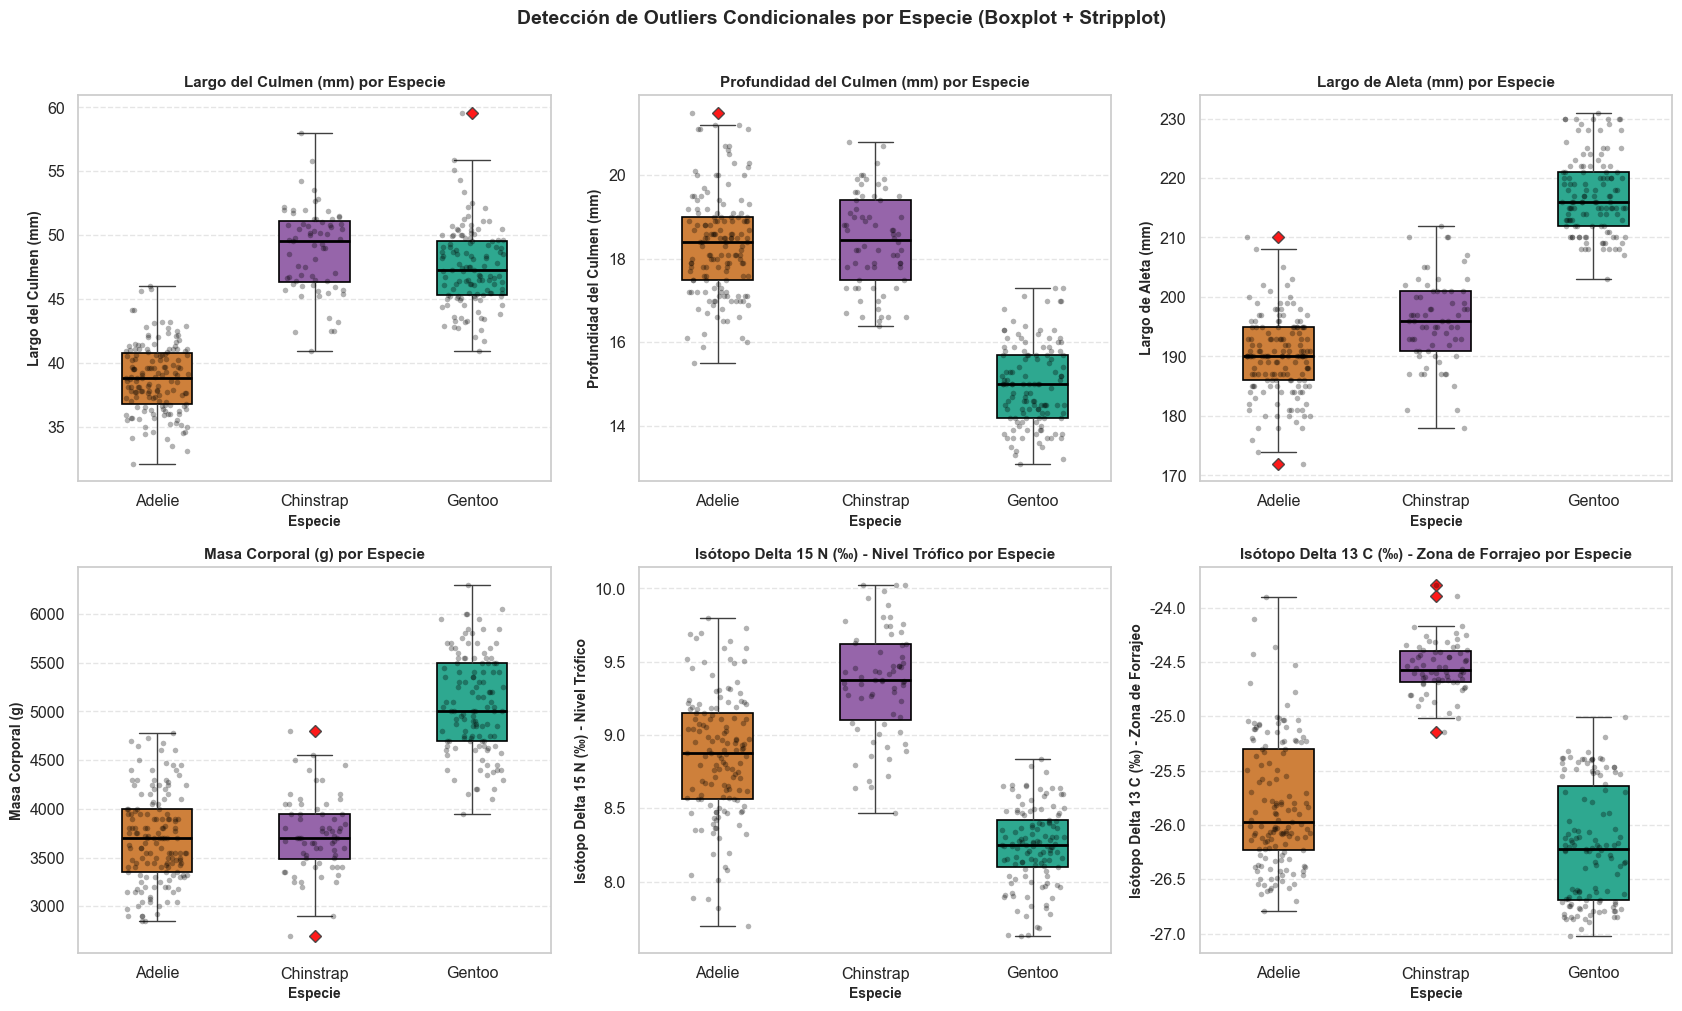

In [17]:
# 2. Boxplots Estratificados por Especie (Detección Condicional de Outliers)
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

for i, (col, meta) in enumerate(continuous_vars.items()):
    ax = axes[i]
    sns.boxplot(
        data=df,
        x="species_short",
        y=col,
        palette=SPECIES_COLORS,
        ax=ax,
        width=0.45,
        boxprops=dict(edgecolor="black", linewidth=1.2),
        medianprops=dict(color="black", linewidth=2),
        flierprops=dict(marker="D", markerfacecolor="red", markersize=6, alpha=0.9)
    )
    
    # Superponemos los puntos reales con stripplot
    sns.stripplot(
        data=df,
        x="species_short",
        y=col,
        color="black",
        alpha=0.3,
        size=4,
        jitter=0.2,
        ax=ax
    )
    
    ax.set_title(f"{meta['label']} por Especie", fontsize=11, weight="bold")
    ax.set_xlabel("Especie", fontsize=10, weight="bold")
    ax.set_ylabel(meta["label"], fontsize=10, weight="bold")
    ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.suptitle("Detección de Outliers Condicionales por Especie (Boxplot + Stripplot)", fontsize=14, weight="bold", y=1.01)
plt.tight_layout()
plt.show()

In [18]:
# 3. Algoritmo formal de Tukey para cuantificar e identificar los Outliers
outlier_records = []

for col, meta in continuous_vars.items():
    for sp in ["Adelie", "Chinstrap", "Gentoo"]:
        sub = df[df["species_short"] == sp]
        s = sub[col].dropna()
        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1
        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr
        
        out_mask = (sub[col] < lower_limit) | (sub[col] > upper_limit)
        out_df = sub[out_mask]
        
        for idx, row in out_df.iterrows():
            outlier_records.append({
                "Variable": meta["label"],
                "Especie": sp,
                "ID Individuo": row.get("Individual ID", f"Fila {idx}"),
                "Sexo": row.get("Sex", "Desconocido"),
                "Valor Medido": row[col],
                "Límite Inf (Q1 - 1.5 IQR)": round(lower_limit, 2),
                "Límite Sup (Q3 + 1.5 IQR)": round(upper_limit, 2),
                "Tipo de Outlier": "Extremo Superior" if row[col] > upper_limit else "Extremo Inferior"
            })

df_outliers = pd.DataFrame(outlier_records)
print(f"=== Total de Outliers Identificados por Especie: {len(df_outliers)} ===")
display(df_outliers)

=== Total de Outliers Identificados por Especie: 9 ===


,Variable,Especie,ID Individuo,Sexo,Valor Medido,Límite Inf (Q1 - 1.5 IQR),Límite Sup (Q3 + 1.5 IQR),Tipo de Outlier
0,Largo del Culmen (mm),Gentoo,N56A2,MALE,59.60000,38.92,55.92,Extremo Superior
1,Profundidad del Culmen (mm),Adelie,N10A2,MALE,21.50000,15.25,21.25,Extremo Superior
2,Largo de Aleta (mm),Adelie,N18A1,FEMALE,172.00000,172.50,208.50,Extremo Inferior
3,Largo de Aleta (mm),Adelie,N72A2,MALE,210.00000,172.50,208.50,Extremo Superior
4,Masa Corporal (g),Chinstrap,N69A2,MALE,4800.00000,2793.75,4643.75,Extremo Superior
5,Masa Corporal (g),Chinstrap,N72A1,FEMALE,2700.00000,2793.75,4643.75,Extremo Inferior
6,Isótopo Delta 13 C (‰) - Zona de Forrajeo,Chinstrap,N61A1,FEMALE,-23.89017,-25.11,-23.97,Extremo Superior
7,Isótopo Delta 13 C (‰) - Zona de Forrajeo,Chinstrap,N67A2,FEMALE,-25.14550,-25.11,-23.97,Extremo Inferior
8,Isótopo Delta 13 C (‰) - Zona de Forrajeo,Chinstrap,N96A1,MALE,-23.78767,-25.11,-23.97,Extremo Superior


#### Hallazgos Críticos en la Detección de Outliers:
1. **Outliers Globales = 0:** Al calcular los boxplots sobre la totalidad de la muestra, el rango intercuartílico $IQR$ se expande debido a la coexistencia de especies grandes (*Gentoo*) y pequeñas (*Adelie*), por lo que **ningún dato califica como outlier global**.
2. **Outliers Condicionales a la Especie:** Al estratificar por especie, el boxplot revela individuos atípicos genuinos:
   * **Gentoo:** Un pingüino con un culmen extremadamente largo de **59.6 mm** (límite superior: 55.92 mm).
   * **Adelie:** Un individuo con profundidad de culmen de **21.5 mm** y dos con aletas atípicas (172 mm y 210 mm).
   * **Chinstrap:** Dos outliers de peso corporal: uno extremadamente pesado de **4800 g** y otro liviano de **2700 g**.
   * Estos valores representan variaciones biológicas extremas (o dimorfismo muy acentuado), pero corresponden a registros ecológicos válidos, por lo que **no deben ser eliminados** del dataset.

## 7. Análisis Bivariado, Multivariado y Dimorfismo Sexual

### 7.1. Relación Crucial: Largo vs. Profundidad del Pico (Paradoja de Simpson)
Evaluamos la asociación entre el largo y la profundidad del pico a nivel global frente al comportamiento dentro de cada especie.

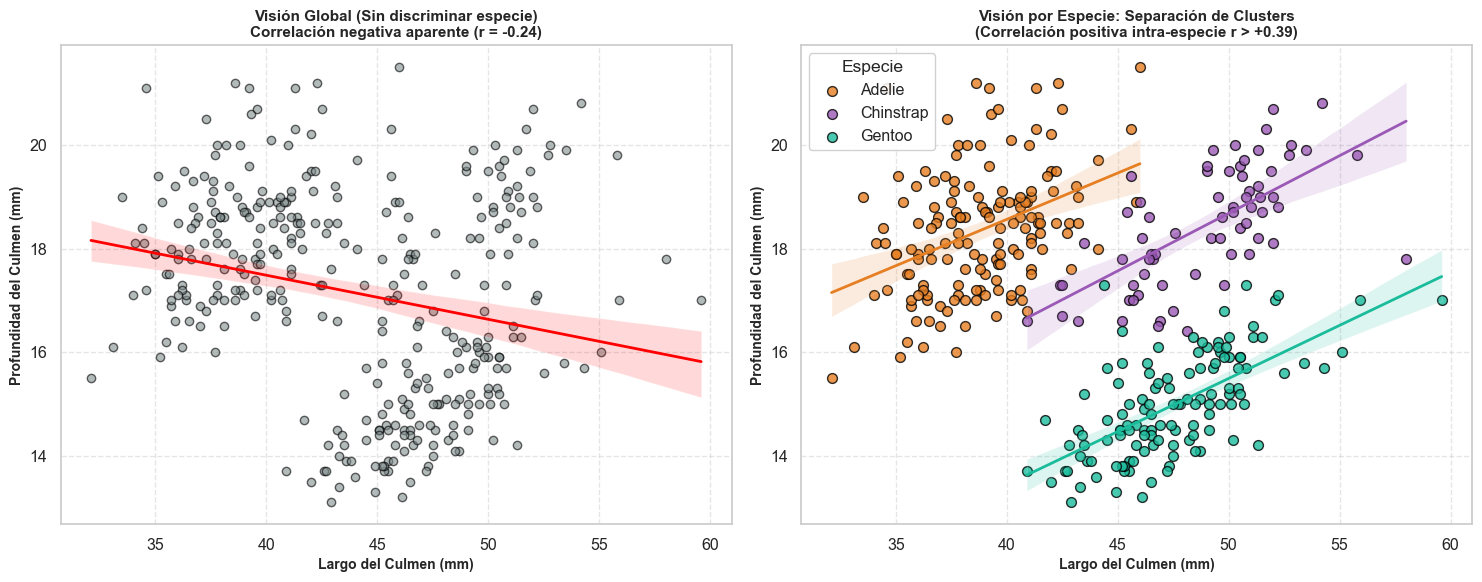

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Dispersión global (Paradoja de Simpson)
sns.regplot(
    data=df,
    x="culmen_length_mm",
    y="culmen_depth_mm",
    ax=axes[0],
    scatter_kws=dict(alpha=0.6, color="#7f8c8d", edgecolors="black"),
    line_kws=dict(color="red", linewidth=2)
)
axes[0].set_title("Visión Global (Sin discriminar especie)\nCorrelación negativa aparente (r = -0.24)", fontsize=11, weight="bold")
axes[0].set_xlabel("Largo del Culmen (mm)", fontsize=10, weight="bold")
axes[0].set_ylabel("Profundidad del Culmen (mm)", fontsize=10, weight="bold")
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Dispersión por Especie
for sp, color in SPECIES_COLORS.items():
    sub = df[df["species_short"] == sp]
    sns.regplot(
        data=sub,
        x="culmen_length_mm",
        y="culmen_depth_mm",
        ax=axes[1],
        color=color,
        label=sp,
        scatter_kws=dict(alpha=0.8, edgecolors="black", s=50),
        line_kws=dict(linewidth=2)
    )

axes[1].set_title("Visión por Especie: Separación de Clusters\n(Correlación positiva intra-especie r > +0.39)", fontsize=11, weight="bold")
axes[1].set_xlabel("Largo del Culmen (mm)", fontsize=10, weight="bold")
axes[1].set_ylabel("Profundidad del Culmen (mm)", fontsize=10, weight="bold")
axes[1].legend(title="Especie", loc="upper left", framealpha=0.9)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 7.2. Alometría y Dimorfismo Sexual: Largo de Aleta vs. Masa Corporal

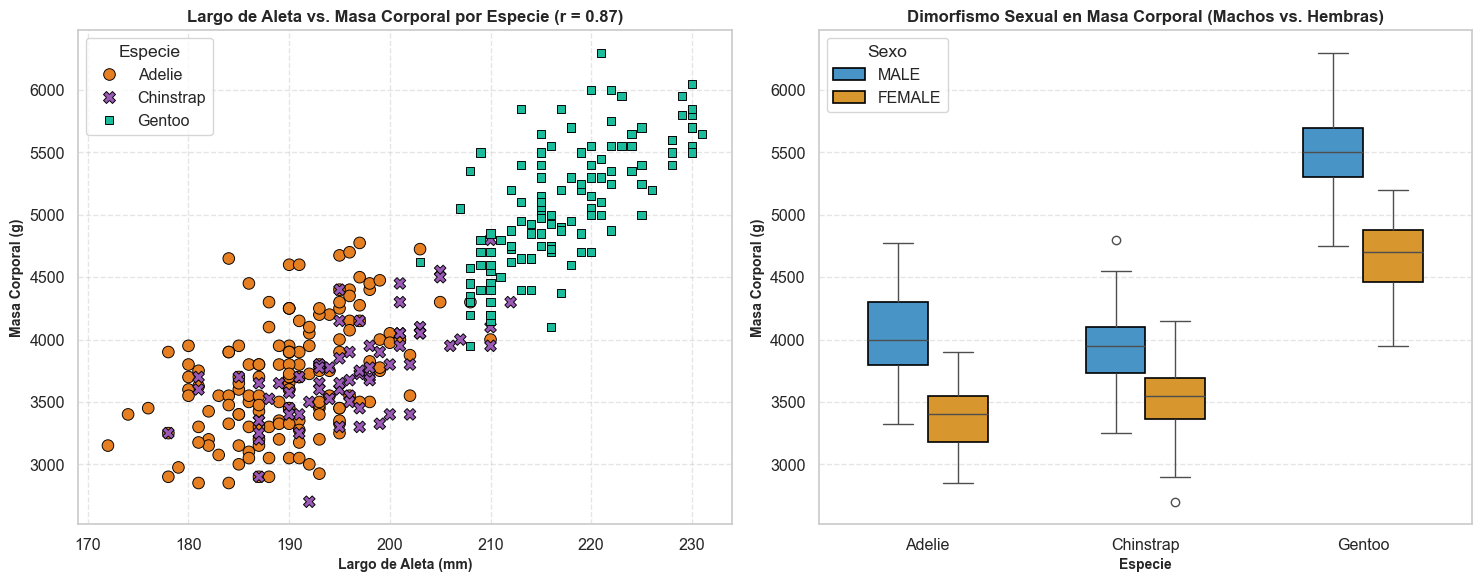

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Flipper Length vs Body Mass
sns.scatterplot(
    data=df,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species_short",
    palette=SPECIES_COLORS,
    style="species_short",
    s=70,
    edgecolor="black",
    ax=axes[0]
)
axes[0].set_title("Largo de Aleta vs. Masa Corporal por Especie (r = 0.87)", fontsize=12, weight="bold")
axes[0].set_xlabel("Largo de Aleta (mm)", fontsize=10, weight="bold")
axes[0].set_ylabel("Masa Corporal (g)", fontsize=10, weight="bold")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(title="Especie")

# Dimorfismo sexual en masa corporal
df_clean_sex = df.dropna(subset=["Sex"])
sns.boxplot(
    data=df_clean_sex,
    x="species_short",
    y="body_mass_g",
    hue="Sex",
    palette={"MALE": "#3498db", "FEMALE": "#f39c12"},
    ax=axes[1],
    width=0.55,
    boxprops=dict(edgecolor="black", linewidth=1.2)
)
axes[1].set_title("Dimorfismo Sexual en Masa Corporal (Machos vs. Hembras)", fontsize=12, weight="bold")
axes[1].set_xlabel("Especie", fontsize=10, weight="bold")
axes[1].set_ylabel("Masa Corporal (g)", fontsize=10, weight="bold")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)
axes[1].legend(title="Sexo", loc="upper left")

plt.tight_layout()
plt.show()

### 7.3. Matrices de Correlación (Pearson y Spearman)
Calculamos el grado de asociación lineal (Pearson) y monótona (Spearman) entre todas las variables continuas.

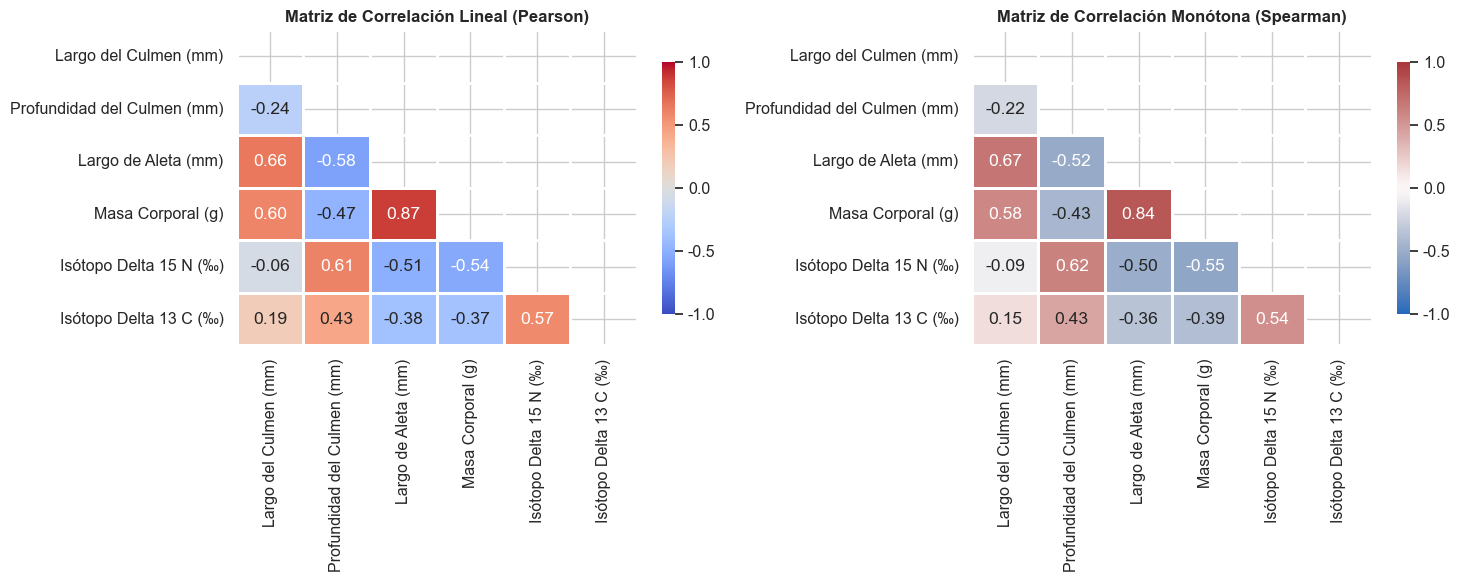

In [21]:
corr_vars = list(continuous_vars.keys())
labels_corr = [meta["label"].split(" - ")[0] for meta in continuous_vars.values()]

corr_pearson = df[corr_vars].corr(method="pearson")
corr_spearman = df[corr_vars].corr(method="spearman")

# Máscara booleana: oculta el triángulo superior Y la diagonal (k=0)
mask = np.triu(np.ones_like(corr_pearson, dtype=bool), k=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Pearson
sns.heatmap(
    corr_pearson,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[0],
    xticklabels=labels_corr,
    yticklabels=labels_corr,
    linewidths=1,
    cbar_kws={"shrink": 0.8}
)
axes[0].set_title("Matriz de Correlación Lineal (Pearson)", fontsize=12, weight="bold")

# Spearman
sns.heatmap(
    corr_spearman,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    ax=axes[1],
    xticklabels=labels_corr,
    yticklabels=labels_corr,
    linewidths=1,
    cbar_kws={"shrink": 0.8}
)
axes[1].set_title("Matriz de Correlación Monótona (Spearman)", fontsize=12, weight="bold")

plt.tight_layout()
plt.show()

## 8. Conclusiones Finales del Análisis Exploratorio de Datos (EDA)

1. **Integridad del Dataset y Mecanismos de Nulidad (`missingno`):**
   * La base exhibe una integridad sobresaliente (>96% de completitud global en todas las variables biométricas).
   * Se identificaron únicamente 2 registros con pérdida simultánea de las 4 medidas morfológicas primarias (filas 3 y 339), evidenciando un mecanismo de pérdida completamente aleatorio (**MCAR**) por fallas en la captura de campo.
   * La variable `Sex` requirió estandarización al detectar 11 valores nulos y un artefacto de carga de datos (`.`), mientras que las firmas isotópicas presentaron faltantes secundarios (14 y 13 casos) correlacionados entre sí por preservación de muestras de sangre.

2. **Demografía y Segregación Insular en el Archipiélago Palmer:**
   * La muestra comprende 344 pingüinos: **44.2% Adelie** (152), **36.0% Gentoo** (124) y **19.8% Chinstrap** (68).
   * Se demostró una estricta especialización de hábitat: *Chinstrap* anida exclusivamente en **Isla Dream**, *Gentoo* exclusivamente en **Punta Biscoe / Islas Biscoe**, mientras que *Adelie* es la única especie generalista presente en las tres islas (Torgersen, Dream y Biscoe).

3. **Comportamiento Probabilístico y Test Formal de Normalidad (Shapiro-Wilk):**
   * A nivel poblacional global, las variables morfológicas muestran bimodalidad, asimetrías y coeficientes de curtosis platicúrticos ($p < 0.0001$), lo que representa un **artefacto estadístico por agregación de especies heterogéneas**.
   * Al estratificar por taxón, las distribuciones se tornan marcadamente simétricas y unimodales. El contraste de Shapiro-Wilk con $\alpha = 0.05$ valida que en *Chinstrap* el 100% de las variables continuas son normales, mientras que en *Adelie* y *Gentoo* la mayoría no rechaza $H_0$, demostrándose que las pequeñas desviaciones se deben al dimorfismo sexual y a individuos atípicos individuales.

4. **Detección Estratificada de Outliers (Criterio IQR de Tukey):**
   * **Paradoja de Escala:** El análisis univariado global arrojó **0 outliers**, ya que el solapamiento de rangos entre especies infla artificialmente el rango intercuartílico ($IQR$).
   * **Detección Condicional:** Al calcular los umbrales $[Q_1 - 1.5\,IQR,\, Q_3 + 1.5\,IQR]$ dentro de cada especie, emergieron 9 individuos con morfología extrema (ej. *Gentoo* con pico de 59.6 mm, dos *Chinstrap* en los límites de peso de 2700 g y 4800 g, y dos *Adelie* con aletas atípicas). Al ser registros biológicos válidos de animales adultos, **no deben ser descartados** en etapas de modelado.

5. **Paradoja de Simpson, Alometría y Dimorfismo Sexual:**
   * **Paradoja de Simpson en la morfología del pico:** A nivel agregado, la longitud y profundidad del culmen presentan correlación lineal negativa ($r = -0.24$). Sin embargo, al controlar por la variable de confusión (especie), la correlación se revierte a fuertemente positiva en las tres poblaciones ($r_{Adelie} = +0.39$, $r_{Gentoo} = +0.65$, $r_{Chinstrap} = +0.65$), demostrando el peligro de extraer conclusiones sin estratificar.
   * **Alometría Masa-Aleta:** El largo de aleta y el peso exhiben una correlación muy fuerte ($r = +0.87$), con *Gentoo* ocupando un clúster macro-somático separado (>4.5 kg, aletas >210 mm).
   * **Dimorfismo Sexual Sistemático:** En las tres especies, los machos superan de forma estadísticamente significativa a las hembras en peso (entre 400 g y 600 g adicionales) y en dimensiones de culmen y aleta.

6. **Estructura de Correlación Lineal (Pearson) y Monótona (Spearman):**
   * La comparación triangular de Pearson y Spearman evidencia relaciones prevalentemente lineales en las variables alométricas ($r \approx \rho \approx 0.87$), confirmando que no existen dependencias fuertemente no lineales o distorsiones severas por asimetrías extremas en las dimensiones corporales del pingüino.
